# Position decoding: Naive Bayes vs. NB+continuity vs. Transformer

Three decoders that map population spiking activity to allocentric position, all trained on the same `bat_data_loader` train/valid/test split:

1. **`NaiveBayes_Decoder`** (Zhang et al. 1998 — "Bayesian 1-step") — per-session Poisson rate maps fit on training timepoints; argmax of the log-posterior at each timestep, independently.
2. **`NaiveBayes_Continuity_Decoder`** (Zhang et al. 1998 — "Bayesian 2-step") — same rate maps as #1, but adds a Gaussian transition prior `P(x_{t-1} | x_t)` with width `σ_t = c · U(x_t)`, where `U(x)` is the per-bin average instantaneous speed estimated from training data. Decoded greedy-forward per flight.
3. **`Bat_Transformer_Decoder`** — RoPE transformer that inverts `Bat_Transformer`. Per-session `nn.Linear(num_neurons, latent_dim)` readins serve as neuron-specific embeddings, followed by transformer encoder layers and a shared linear head to z-scored 3D position.

All three decoders are evaluated on held-out test data; we report 2D (x, y) and 3D (x, y, z) decoding error in meters per session.

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import numpy as np
import pandas as pd
import torch
from torch import nn
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

sys.path.append(os.path.expanduser('~/Documents/code/utils'))
sys.path.append(os.path.expanduser('~/Documents/code/digitalbat'))

from digitalbat.datasets.data import bat_data_loader
from digitalbat.models.decoder import (
    Bat_Transformer_Decoder,
    NaiveBayes_Decoder,
    NaiveBayes_Continuity_Decoder,
    bat_decoder_trainer,
)
from digitalbat.utility.utils import set_random_state

seed = 1
set_random_state(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Toggle synthetic-train comparison.  When True, every training cell below
# loops over ('real', 'synthetic') and comparison plots include a synthetic
# panel.  Set False to skip all synthetic work.
RUN_SYNTHETIC = True
device


'cuda'

## 1. Dataloader

Same configuration as `preprocess-data-v0j-share.ipynb` so the train/valid/test split lines up with the encoder analyses.

In [2]:
session_names = [
    'Dataset_3_14543_240419',
    'Dataset_3_14543_240420',
    'Dataset_3_14543_240421',
    'Dataset_3_29959_240402',
    'Dataset_3_29959_240403',
    'Dataset_3_29959_240404',
    'Dataset_2_14445_231208',
    'Dataset_2_14445_231209',
    'Dataset_1_32622_231009',
    'Dataset_1_32622_231010',
    'Dataset_1_32622_231007',
    'Dataset_2_14611_231208',
    'Dataset_2_14611_231209',
    'Dataset_3_00000_240402',
    'Dataset_3_00000_240403',
    'Dataset_3_00000_240404',
    'Dataset_3_00000_240405',
    'Dataset_3_29959_240405',
]

data_config = dict(
    use_speed_head_dir=False,
    use_IMU_flag=False,
    use_click_flag=False,
    use_LFP_flag=False,
    use_ripple_flag=False,
    only_flight_flag=True,
    no_3d_location=False,
    spike_count_flag=True,
    bin_width=0.10,
    split_flights_for_train='random',
    type_train_num=1,
    type_valid_num=1,
    special_id_count_thresh=3,
    only_use_special_id_4train_flag=False,
    shuffle_flag=True,
    time_shuffle_for_trajecotry_flag=False,
    split_each_trajectory_flag=True,
    window_size=None,
    stride_train=None,
    stride_test=None,
    batch_size_train=None,
    batch_size_test=None,
    session_names=session_names,
    parent_folder='/mnt/s5/Adam/Angelo/NP_datasets/',
    max_acceleration=50,
)
dataloaders, behavior_dim, unit_num_dict, meta_info_dict = bat_data_loader(**data_config)
print(f'behavior_dim = {behavior_dim}, sessions = {len(unit_num_dict)}')
unit_num_dict

  Acceleration filter: removed 1/37 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/136 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 9/154 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/131 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/79 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/78 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/77 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/82 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 1/98 flights (peak |acc| > 50 m/s²)
  Acceleration filter: removed 4/112 flights (peak |acc| > 50 m/s²)
behavior_dim = 3, sessions = 18


{'Dataset_3_14543_240419': 289,
 'Dataset_3_14543_240420': 126,
 'Dataset_3_14543_240421': 100,
 'Dataset_3_29959_240402': 317,
 'Dataset_3_29959_240403': 191,
 'Dataset_3_29959_240404': 190,
 'Dataset_2_14445_231208': 237,
 'Dataset_2_14445_231209': 168,
 'Dataset_1_32622_231009': 95,
 'Dataset_1_32622_231010': 54,
 'Dataset_1_32622_231007': 167,
 'Dataset_2_14611_231208': 236,
 'Dataset_2_14611_231209': 186,
 'Dataset_3_00000_240402': 394,
 'Dataset_3_00000_240403': 207,
 'Dataset_3_00000_240404': 147,
 'Dataset_3_00000_240405': 122,
 'Dataset_3_29959_240405': 143}

In [3]:
# Synthetic-train dataloaders share the same valid/test as `dataloaders`
# (by reference); only `train` spikes are Poisson samples from a smoothed
# 3D rate map fit on real training data.
if RUN_SYNTHETIC:
    from digitalbat.datasets.synthetic import make_synthetic_train_dataloaders
    syn_dataloaders, simulators = make_synthetic_train_dataloaders(
        dataloaders, meta_info_dict, dt=data_config['bin_width'], seed=seed)
    assert syn_dataloaders['valid'] is dataloaders['valid']
    assert syn_dataloaders['test'] is dataloaders['test']
else:
    syn_dataloaders, simulators = None, None


## 2. Transformer decoder

Per-session readins → RoPE transformer → linear head to z-scored 3D position. Loss is MSE on z-scored space, masked to valid timesteps. The first 3 channels of `batch.behavior` are the (z-scored) (x, y, z) targets.

We use **Optuna (TPE)** to search dropout, readin dropout, latent_dim, ff_dim, num_layers, and input_transform. Each trial trains up to 1000 epochs with early stopping (patience 30). The final model is then refit with the best params and patience 50.

In [4]:
import optuna

# Fixed (non-searched) hyperparameters
fixed_config = dict(
    input_dim_dict=unit_num_dict,
    output_dim=3,
    num_heads=4,
    final_activation=nn.Identity(),
)

MAX_EPOCHS = 1000
TRIAL_PATIENCE = 30
N_TRIALS = 20


def make_model(params):
    return Bat_Transformer_Decoder(
        latent_dim=params['latent_dim'],
        ff_dim=params['ff_dim'],
        num_layers=params['num_layers'],
        dropout_prob=params['dropout_prob'],
        readin_dropout=params['readin_dropout'],
        input_transform=params['input_transform'],
        **fixed_config,
    )


def objective(trial):
    params = dict(
        latent_dim=trial.suggest_categorical('latent_dim', [32, 64, 128]),
        ff_dim=trial.suggest_categorical('ff_dim', [32, 64, 128]),
        num_layers=trial.suggest_int('num_layers', 1, 3),
        dropout_prob=trial.suggest_float('dropout_prob', 0.0, 0.5),
        readin_dropout=trial.suggest_float('readin_dropout', 0.0, 0.3),
        input_transform=trial.suggest_categorical('input_transform', ['identity', 'sqrt']),
    )
    set_random_state(seed)
    model = make_model(params)
    best_score, _, _ = bat_decoder_trainer(
        model=model,
        dataloaders=dataloaders,
        device=device,
        pos_dims=3,
        n_epochs=MAX_EPOCHS,
        lr=1e-3,
        weight_decay=0.01,
        loss_fn=nn.MSELoss(),
        valid_stat='mean',
        early_stopping_patience=TRIAL_PATIENCE,
        save_model=False,
    )
    return best_score  # higher (less-negative MSE) is better

In [5]:
import pickle

os.makedirs('./out/bat_decoder', exist_ok=True)
transformer_study_path = f'./out/bat_decoder/bat_decoder_seed_{seed}_optuna.pkl'

if os.path.exists(transformer_study_path):
    with open(transformer_study_path, 'rb') as f:
        transformer_study = pickle.load(f)
    print(f'Loaded existing study with {len(transformer_study.trials)} trials')
else:
    sampler = optuna.samplers.TPESampler(seed=seed)
    transformer_study = optuna.create_study(direction='maximize', sampler=sampler)

# Top up to N_TRIALS
remaining = max(0, N_TRIALS - len(transformer_study.trials))
if remaining > 0:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    transformer_study.optimize(objective, n_trials=remaining, show_progress_bar=True)
    with open(transformer_study_path, 'wb') as f:
        pickle.dump(transformer_study, f)

print(f'\nBest score (mean -MSE per dim): {transformer_study.best_value:.4f}')
print('Best params:')
for k, v in transformer_study.best_params.items():
    print(f'  {k}: {v}')
trials_df = transformer_study.trials_dataframe()
trials_df.sort_values('value', ascending=False).head(10)

Loaded existing study with 20 trials

Best score (mean -MSE per dim): -0.2863
Best params:
  latent_dim: 128
  ff_dim: 32
  num_layers: 1
  dropout_prob: 0.3026498713680113
  readin_dropout: 0.18620747152988154
  input_transform: identity


,number,value,datetime_start,datetime_complete,duration,params_dropout_prob,params_ff_dim,params_input_transform,params_latent_dim,params_num_layers,params_readin_dropout,state
15,15,-0.286285,2026-04-30 11:08:18.840129,2026-04-30 11:09:06.377684,0 days 00:00:47.537555,0.302650,32,identity,128,1,0.186207,COMPLETE
12,12,-0.288571,2026-04-30 11:06:11.926714,2026-04-30 11:07:02.698855,0 days 00:00:50.772141,0.221107,32,identity,128,1,0.181396,COMPLETE
13,13,-0.290705,2026-04-30 11:07:02.699472,2026-04-30 11:07:41.592551,0 days 00:00:38.893079,0.305558,32,identity,128,1,0.193649,COMPLETE
14,14,-0.291083,2026-04-30 11:07:41.593090,2026-04-30 11:08:18.839529,0 days 00:00:37.246439,0.254438,32,identity,128,1,0.184603,COMPLETE
4,4,-0.297926,2026-04-30 11:02:14.781200,2026-04-30 11:02:39.135925,0 days 00:00:24.354725,0.339418,32,sqrt,128,1,0.063488,COMPLETE
0,0,-0.299033,2026-04-30 10:59:54.405690,2026-04-30 11:00:46.284671,0 days 00:00:51.878981,0.172780,32,identity,64,1,0.119030,COMPLETE
1,1,-0.299131,2026-04-30 11:00:46.285301,2026-04-30 11:01:20.357131,0 days 00:00:34.071830,0.070193,64,sqrt,128,2,0.059430,COMPLETE
16,16,-0.299361,2026-04-30 11:09:06.378313,2026-04-30 11:09:30.618063,0 days 00:00:24.239750,0.221342,128,identity,128,1,0.175024,COMPLETE
19,19,-0.303852,2026-04-30 11:10:44.733141,2026-04-30 11:11:07.779787,0 days 00:00:23.046646,0.196002,128,identity,128,1,0.136583,COMPLETE
2,2,-0.311607,2026-04-30 11:01:20.357753,2026-04-30 11:01:51.974671,0 days 00:00:31.616918,0.439071,32,sqrt,128,1,0.029504,COMPLETE


In [6]:
# Train Bat_Transformer_Decoder.  When RUN_SYNTHETIC, also train an
# identical architecture on the synthetic-train dataloaders (same valid /
# test).  Both checkpoints coexist on disk via the `_synthetic` suffix.
best_params = transformer_study.best_params
substr = '_'.join(f'{k}_{v:.2f}' if isinstance(v, float) else f'{k}_{v}'
                  for k, v in best_params.items())
model_path_template = f'./out/bat_decoder/bat_decoder_seed_{seed}_{substr}{{suffix}}.pth'

modes = ['real'] + (['synthetic'] if RUN_SYNTHETIC else [])
mode_dataloaders = {'real': dataloaders, 'synthetic': syn_dataloaders}

decoder_models, decoder_paths, decoder_curves = {}, {}, {}
for mode in modes:
    suffix = '' if mode == 'real' else f'_{mode}'
    set_random_state(seed)
    decoder_models[mode] = make_model(best_params)
    decoder_paths[mode] = model_path_template.format(suffix=suffix)
    if mode == 'real':
        n_params = sum(p.numel() for p in decoder_models[mode].parameters()
                       if p.requires_grad)
        print(f'Final model params: {n_params:,}')
    if os.path.exists(decoder_paths[mode]):
        print(f'[{mode}] loading existing weights from {decoder_paths[mode]}')
        decoder_models[mode].load_state_dict(
            torch.load(decoder_paths[mode], map_location=device))
        decoder_models[mode] = decoder_models[mode].to(device)
        decoder_curves[mode] = None
    else:
        best_score, _, val_scores = bat_decoder_trainer(
            model=decoder_models[mode],
            dataloaders=mode_dataloaders[mode],
            device=device,
            pos_dims=3,
            n_epochs=MAX_EPOCHS,
            lr=1e-3,
            weight_decay=0.01,
            loss_fn=nn.MSELoss(),
            valid_stat='mean',
            early_stopping_patience=50,
            save_model=True,
            model_name=decoder_paths[mode],
        )
        print(f'[{mode}] best_score (mean -MSE per dim): {best_score:.4f}')
        decoder_curves[mode] = val_scores

# Backwards-compatible aliases used downstream.
decoder_model = decoder_models['real']
model_path = decoder_paths['real']
val_scores = decoder_curves['real']
if RUN_SYNTHETIC:
    decoder_model_synthetic = decoder_models['synthetic']
    model_path_synthetic = decoder_paths['synthetic']
    val_scores_synthetic = decoder_curves['synthetic']


Final model params: 508,835
[real] loading existing weights from ./out/bat_decoder/bat_decoder_seed_1_latent_dim_128_ff_dim_32_num_layers_1_dropout_prob_0.30_readin_dropout_0.19_input_transform_identity.pth
[synthetic] loading existing weights from ./out/bat_decoder/bat_decoder_seed_1_latent_dim_128_ff_dim_32_num_layers_1_dropout_prob_0.30_readin_dropout_0.19_input_transform_identity_synthetic.pth


In [7]:
if val_scores is not None:
    plt.figure(figsize=(5, 3))
    plt.plot(val_scores)
    plt.xlabel('Epoch')
    plt.ylabel('Mean -MSE per dim (z-scored)')
    plt.title('Decoder validation curve')
    plt.tight_layout()
    plt.show()

### 2a. Evaluate the transformer decoder on test data

We un-z-score the predictions per session using `meta_info_dict['behavior_mean']` / `behavior_std`, then compute 2D (x, y) error in meters at each valid timestep.

In [8]:
def parse_bat(session_name):
    """`Dataset_3_14543_240419` → '14543'."""
    return session_name.split('_')[2]


def _eval_decoder_records(model, dataloaders, meta_info_dict, device):
    """Run the trained decoder on real test+train; return {split: list[record]}."""
    records = {'test': [], 'train': []}
    model.eval()
    with torch.no_grad():
        for split in ('test', 'train'):
            for session_name, session_data in dataloaders[split].items():
                bm = meta_info_dict['behavior_mean'][session_name].squeeze()
                bs = meta_info_dict['behavior_std'][session_name].squeeze()
                bat = parse_bat(session_name)
                for batch in session_data:
                    X = batch.spike.to(device)
                    m = batch.mask.to(device)
                    y_true_z = batch.behavior[:, :, :3].numpy()
                    y_pred_z = model(session_name, X, m).cpu().numpy()
                    mask_np = batch.mask.numpy().astype(bool)
                    B, T = mask_np.shape
                    y_true = y_true_z * bs[None, None, :3] + bm[None, None, :3]
                    y_pred = y_pred_z * bs[None, None, :3] + bm[None, None, :3]
                    fpi_per_t = np.broadcast_to(
                        batch.flight_path_index.numpy()[:, None], (B, T))
                    t_idx_per = np.broadcast_to(np.arange(T)[None, :], (B, T))
                    y_true_flat = y_true[mask_np]
                    y_pred_flat = y_pred[mask_np]
                    fpi_flat = fpi_per_t[mask_np].astype(int)
                    t_flat = t_idx_per[mask_np].astype(int)
                    err_2d = np.sqrt(((y_true_flat[:, :2] - y_pred_flat[:, :2]) ** 2).sum(axis=1))
                    err_3d = np.sqrt(((y_true_flat - y_pred_flat) ** 2).sum(axis=1))
                    for i in range(len(err_2d)):
                        records[split].append({
                            'bat': bat,
                            'session': session_name,
                            'flight_id': int(fpi_flat[i]),
                            't_idx': int(t_flat[i]),
                            'x_true': float(y_true_flat[i, 0]),
                            'y_true': float(y_true_flat[i, 1]),
                            'z_true': float(y_true_flat[i, 2]),
                            'x_pred': float(y_pred_flat[i, 0]),
                            'y_pred': float(y_pred_flat[i, 1]),
                            'z_pred': float(y_pred_flat[i, 2]),
                            'err_2d': float(err_2d[i]),
                            'err_3d': float(err_3d[i]),
                        })
    return records


transformer_records = _eval_decoder_records(
    decoder_models['real'], dataloaders, meta_info_dict, device)
transformer_df = pd.DataFrame(transformer_records['test']).assign(decoder='transformer')
transformer_train_df = pd.DataFrame(transformer_records['train']).assign(decoder='transformer')
if RUN_SYNTHETIC:
    transformer_records_synthetic = _eval_decoder_records(
        decoder_models['synthetic'], dataloaders, meta_info_dict, device)
    transformer_df_synthetic = pd.DataFrame(
        transformer_records_synthetic['test']).assign(decoder='transformer')
    transformer_train_df_synthetic = pd.DataFrame(
        transformer_records_synthetic['train']).assign(decoder='transformer')
transformer_df.groupby('session')[['err_2d', 'err_3d']].median().sort_values('err_2d')


,err_2d,err_3d
session,,
Dataset_3_00000_240403,0.171835,0.182515
Dataset_3_00000_240402,0.179335,0.182717
Dataset_3_29959_240402,0.209417,0.223434
Dataset_3_29959_240404,0.219008,0.234775
Dataset_3_29959_240403,0.224051,0.243702
Dataset_3_14543_240419,0.241247,0.316650
Dataset_1_32622_231010,0.262182,0.282830
Dataset_3_14543_240421,0.267054,0.289140
Dataset_3_14543_240420,0.320797,0.331156


## 3. Naive Bayes decoder

Per session we fit **two** Naive Bayes decoders independently:
- `nb_2d`: 2D rate maps over (x, y) — used for 2D error.
- `nb_3d`: 3D rate maps over (x, y, z) — used for 3D error.

Fitting them separately is fairer than projecting a 3D decoder to 2D, because 3D occupancy is sparser per voxel and the 2D map marginalizes over z. Bin edges come from `meta_info_dict['r_lim']`. Spikes are raw counts; positions are recovered from the z-scored `batch.behavior` using session-specific mean/std.

We also use **Optuna** to search NB hyperparameters on the validation set: smoothing kernel `sigma` (in bins), grid resolution `n_bins` per axis, `min_occupancy` (threshold for which bins are "in support" before smoothing), and `use_uniform_prior` (uniform prior over support vs. empirical-occupancy prior). The objective is the mean across sessions of each session's median position error in meters. A single set of HPs is picked per ndim — the same way the transformer uses one set across sessions.

In [9]:
def gather_session_arrays(loader, behavior_mean, behavior_std):
    """Concatenate spikes / positions / flight_id / t_idx over all batches.

    Returns dict with raw (un-z-scored) positions and raw spike counts on
    valid timesteps only. `flight_id` is `batch.flight_path_index` broadcast
    to per-timestep, and `t_idx` is the within-flight time-bin index — both
    needed to draw per-flight trajectory lines.
    """
    spk_list, beh_list, mask_list, fpi_list = [], [], [], []
    for batch in loader:
        spk_list.append(batch.spike.numpy())
        beh_list.append(batch.behavior.numpy())
        mask_list.append(batch.mask.numpy().astype(bool))
        fpi_list.append(batch.flight_path_index.numpy())
    spikes = np.concatenate(spk_list, axis=0)        # (B, T, K)
    behavior = np.concatenate(beh_list, axis=0)      # (B, T, behavior_dim)
    mask = np.concatenate(mask_list, axis=0)         # (B, T)
    fpi = np.concatenate(fpi_list, axis=0)           # (B,)

    bm = np.asarray(behavior_mean).squeeze()
    bs = np.asarray(behavior_std).squeeze()
    pos = behavior[..., :3] * bs[None, None, :3] + bm[None, None, :3]

    B, T, _ = behavior.shape
    fpi_per_t = np.broadcast_to(fpi[:, None], (B, T))
    t_idx_per = np.broadcast_to(np.arange(T)[None, :], (B, T))

    return {
        'spikes': spikes[mask],
        'pos_x': pos[..., 0][mask],
        'pos_y': pos[..., 1][mask],
        'pos_z': pos[..., 2][mask],
        'flight_id': fpi_per_t[mask].astype(int),
        't_idx': t_idx_per[mask].astype(int),
    }

In [10]:
NB_N_TRIALS = 20

# Pre-gather train + valid arrays per session so each Optuna trial only needs
# to re-fit + re-predict, not re-iterate the dataloader.
session_arrays = {}
for s in dataloaders['test'].keys():
    bm = meta_info_dict['behavior_mean'][s]
    bs = meta_info_dict['behavior_std'][s]
    r_lim = meta_info_dict['r_lim'][s]
    train = gather_session_arrays(dataloaders['train'][s], bm, bs)
    valid = gather_session_arrays(dataloaders['valid'][s], bm, bs)
    if train['spikes'].shape[0] < 100 or valid['spikes'].shape[0] < 10:
        continue
    session_arrays[s] = (train, valid, r_lim)
print(f'NB search using {len(session_arrays)}/{len(dataloaders["test"])} sessions')


def nb_objective(trial, ndim):
    sigma = trial.suggest_float('sigma', 0.5, 4.0)
    n_bins_x = trial.suggest_categorical('n_bins_x', [15, 20, 25, 30, 40, 50])
    n_bins_y = trial.suggest_categorical('n_bins_y', [15, 20, 25, 30, 40, 50])
    min_occ = trial.suggest_int('min_occupancy', 1, 10)
    use_uniform = trial.suggest_categorical('use_uniform_prior', [True, False])
    if ndim == 3:
        n_bins_z = trial.suggest_categorical('n_bins_z', [8, 10, 15, 20])
        n_bins = (n_bins_x, n_bins_y, n_bins_z)
    else:
        n_bins = (n_bins_x, n_bins_y)

    cols = ['pos_x', 'pos_y'] + (['pos_z'] if ndim == 3 else [])
    per_session_med_err = []
    for s, (train, valid, r_lim) in session_arrays.items():
        train_pos = np.column_stack([train[c] for c in cols])
        valid_pos = np.column_stack([valid[c] for c in cols])
        try:
            nb = NaiveBayes_Decoder(
                n_bins=n_bins,
                lims=[tuple(r_lim[d]) for d in range(ndim)],
                sigma=sigma,
                dt=data_config['bin_width'],
                min_occupancy=min_occ,
                use_uniform_prior=use_uniform,
            ).fit(train['spikes'], train_pos)
            pos_dec, _ = nb.predict(valid['spikes'])
            err = np.sqrt(((valid_pos - pos_dec) ** 2).sum(axis=1))
            per_session_med_err.append(np.median(err))
        except Exception:
            # bin/lim choice incompatible with this session → mark trial bad
            return -np.inf
    # mean across sessions of per-session median error (each session weighted equally)
    return -float(np.mean(per_session_med_err))


nb_studies = {}
nb_best = {}
for ndim in (2, 3):
    nb_study_path = f'./out/nb_decoder/nb_decoder_{ndim}d_seed_{seed}_optuna.pkl'
    if os.path.exists(nb_study_path):
        with open(nb_study_path, 'rb') as f:
            nb_studies[ndim] = pickle.load(f)
        print(f'NB-{ndim}D: loaded existing study with {len(nb_studies[ndim].trials)} trials')
    else:
        sampler = optuna.samplers.TPESampler(seed=seed)
        nb_studies[ndim] = optuna.create_study(direction='maximize', sampler=sampler)

    nb_study = nb_studies[ndim]
    remaining = max(0, NB_N_TRIALS - len(nb_study.trials))
    if remaining > 0:
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        nb_study.optimize(lambda t, n=ndim: nb_objective(t, n),
                          n_trials=remaining, show_progress_bar=True)
        with open(nb_study_path, 'wb') as f:
            pickle.dump(nb_study, f)

    nb_best[ndim] = nb_study.best_params
    print(f'NB-{ndim}D best valid err (mean of per-session medians): {-nb_study.best_value:.4f} m')
    print(f'  best params: {nb_study.best_params}')

NB search using 18/18 sessions
NB-2D: loaded existing study with 20 trials
NB-2D best valid err (mean of per-session medians): 0.4879 m
  best params: {'sigma': 0.5182239023980032, 'n_bins_x': 30, 'n_bins_y': 30, 'min_occupancy': 3, 'use_uniform_prior': False}
NB-3D: loaded existing study with 20 trials
NB-3D best valid err (mean of per-session medians): 0.5427 m
  best params: {'sigma': 0.5695804684392846, 'n_bins_x': 30, 'n_bins_y': 40, 'min_occupancy': 1, 'use_uniform_prior': True, 'n_bins_z': 15}


In [11]:
def make_nb(ndim, r_lim, params):
    """Instantiate a NB decoder from Optuna best_params + per-session r_lim."""
    if ndim == 3:
        n_bins = (params['n_bins_x'], params['n_bins_y'], params['n_bins_z'])
    else:
        n_bins = (params['n_bins_x'], params['n_bins_y'])
    return NaiveBayes_Decoder(
        n_bins=n_bins,
        lims=[tuple(r_lim[d]) for d in range(ndim)],
        sigma=params['sigma'],
        dt=data_config['bin_width'],
        min_occupancy=params['min_occupancy'],
        use_uniform_prior=params['use_uniform_prior'],
    )


def _fit_eval_nb(train_loader, test_loader, session_name, meta_info_dict, eval_train_loader=None):
    """Fit NB-2D/3D on `train_loader`; evaluate on `test_loader` (real test) and
    `eval_train_loader` (defaults to `train_loader`).  Returns (records, decoders)
    or (None, None) if too few samples."""
    bm = meta_info_dict['behavior_mean'][session_name]
    bs = meta_info_dict['behavior_std'][session_name]
    r_lim = meta_info_dict['r_lim'][session_name]
    bat = parse_bat(session_name)
    train = gather_session_arrays(train_loader, bm, bs)
    test = gather_session_arrays(test_loader, bm, bs)
    if train['spikes'].shape[0] < 100 or test['spikes'].shape[0] < 10:
        return None, None
    eval_train = (gather_session_arrays(eval_train_loader, bm, bs)
                  if eval_train_loader is not None else train)
    train_pos_2d = np.column_stack([train['pos_x'], train['pos_y']])
    train_pos_3d = np.column_stack([train['pos_x'], train['pos_y'], train['pos_z']])
    test_pos_2d = np.column_stack([test['pos_x'], test['pos_y']])
    test_pos_3d = np.column_stack([test['pos_x'], test['pos_y'], test['pos_z']])
    et_pos_2d = np.column_stack([eval_train['pos_x'], eval_train['pos_y']])
    et_pos_3d = np.column_stack([eval_train['pos_x'], eval_train['pos_y'], eval_train['pos_z']])
    nb_2d = make_nb(2, r_lim, nb_best[2]).fit(train['spikes'], train_pos_2d)
    nb_3d = make_nb(3, r_lim, nb_best[3]).fit(train['spikes'], train_pos_3d)
    records = {'test': [], 'train': []}
    for split, arr, p2d, p3d in [
        ('test', test, test_pos_2d, test_pos_3d),
        ('train', eval_train, et_pos_2d, et_pos_3d),
    ]:
        pos_dec_2d, _ = nb_2d.predict(arr['spikes'])
        pos_dec_3d, _ = nb_3d.predict(arr['spikes'])
        err_2d = np.sqrt(((p2d - pos_dec_2d) ** 2).sum(axis=1))
        err_3d = np.sqrt(((p3d - pos_dec_3d) ** 2).sum(axis=1))
        for i in range(len(err_2d)):
            records[split].append({
                'bat': bat,
                'session': session_name,
                'flight_id': int(arr['flight_id'][i]),
                't_idx': int(arr['t_idx'][i]),
                'x_true': float(p3d[i, 0]),
                'y_true': float(p3d[i, 1]),
                'z_true': float(p3d[i, 2]),
                'x_pred_2d': float(pos_dec_2d[i, 0]),
                'y_pred_2d': float(pos_dec_2d[i, 1]),
                'x_pred_3d': float(pos_dec_3d[i, 0]),
                'y_pred_3d': float(pos_dec_3d[i, 1]),
                'z_pred_3d': float(pos_dec_3d[i, 2]),
                'err_2d': float(err_2d[i]),
                'err_3d': float(err_3d[i]),
            })
    return records, {'2d': nb_2d, '3d': nb_3d}


nb_records_by_mode = {m: {'test': [], 'train': []} for m in modes}
decoders_nb_by_mode = {m: {} for m in modes}

for session_name in dataloaders['test'].keys():
    for mode in modes:
        train_loader = mode_dataloaders[mode]['train'][session_name]
        # For diagnostics on synthetic mode, evaluate the 'train' split on
        # real-train spikes so the train numbers in records are comparable.
        eval_train_loader = (dataloaders['train'][session_name]
                             if mode == 'synthetic' else None)
        rec, dec = _fit_eval_nb(
            train_loader, dataloaders['test'][session_name],
            session_name, meta_info_dict, eval_train_loader=eval_train_loader,
        )
        if rec is None:
            if mode == 'real':
                print(f'  {session_name}: too few samples, skipping')
            continue
        nb_records_by_mode[mode]['test'].extend(rec['test'])
        nb_records_by_mode[mode]['train'].extend(rec['train'])
        decoders_nb_by_mode[mode][session_name] = dec

nb_df = pd.DataFrame(nb_records_by_mode['real']['test']).assign(decoder='naive_bayes')
nb_train_df = pd.DataFrame(nb_records_by_mode['real']['train']).assign(decoder='naive_bayes')
decoders_nb = decoders_nb_by_mode['real']
if RUN_SYNTHETIC:
    nb_df_synthetic = pd.DataFrame(
        nb_records_by_mode['synthetic']['test']).assign(decoder='naive_bayes')
    nb_train_df_synthetic = pd.DataFrame(
        nb_records_by_mode['synthetic']['train']).assign(decoder='naive_bayes')
    decoders_nb_synthetic = decoders_nb_by_mode['synthetic']
nb_df.groupby('session')[['err_2d', 'err_3d']].median().sort_values('err_2d')


,err_2d,err_3d
session,,
Dataset_3_29959_240404,0.283832,0.322167
Dataset_3_00000_240403,0.296924,0.352627
Dataset_3_00000_240402,0.304621,0.313148
Dataset_3_00000_240404,0.376688,0.415504
Dataset_3_29959_240403,0.379686,0.389823
Dataset_3_29959_240405,0.388589,0.466696
Dataset_3_00000_240405,0.398099,0.456901
Dataset_3_14543_240420,0.415036,0.465704
Dataset_2_14445_231208,0.442951,0.633500


## 3b. Naive Bayes + continuity prior (Bayesian 2-step)

Same rate maps as the 1-step NB above, plus a Gaussian transition prior `P(x_{t-1} | x_t)` whose width `σ_t = c · U(x_t)` scales with the per-bin average speed. We pre-compute `U(x)` from consecutive training timesteps within flights (so the speed estimate doesn't bleed across flight boundaries), and decode **greedy-forward per flight** — the prior at step `t` uses the previous step's decoded position and resets at flight boundaries.

We Optuna-search over `c` only (the main hyperparameter per Zhang). The other NB hyperparameters (`sigma`, `n_bins`, `min_occupancy`, prior choice) are **fixed at the values found by the 1-step NB search above**, so the only difference between this decoder and the 1-step NB is the continuity prior. `σ_min` and `σ_max` are clipped to `(0.02, 5.0)` m, well outside the regime where they can fight the data.

In [12]:
NB_CONT_N_TRIALS = 20
NB_CONT_SIGMA_CLIP = (0.02, 5.0)  # σ_t floor/ceiling in METERS


def make_nb_continuity(ndim, r_lim, c_speed, nb_hp):
    """Continuity decoder with NB hyperparameters borrowed from `nb_best`."""
    if ndim == 3:
        n_bins = (nb_hp['n_bins_x'], nb_hp['n_bins_y'], nb_hp['n_bins_z'])
    else:
        n_bins = (nb_hp['n_bins_x'], nb_hp['n_bins_y'])
    return NaiveBayes_Continuity_Decoder(
        c_speed=c_speed,
        sigma_min=NB_CONT_SIGMA_CLIP[0],
        sigma_max=NB_CONT_SIGMA_CLIP[1],
        n_bins=n_bins,
        lims=[tuple(r_lim[d]) for d in range(ndim)],
        sigma=nb_hp['sigma'],
        dt=data_config['bin_width'],
        min_occupancy=nb_hp['min_occupancy'],
        use_uniform_prior=nb_hp['use_uniform_prior'],
    )


def nb_cont_objective(trial, ndim):
    c_speed = trial.suggest_float('c_speed', 0.05, 5.0, log=True)
    nb_hp = nb_best[ndim]
    cols = ['pos_x', 'pos_y'] + (['pos_z'] if ndim == 3 else [])
    per_session_med_err = []
    for s, (train, valid, r_lim) in session_arrays.items():
        train_pos = np.column_stack([train[c] for c in cols])
        valid_pos = np.column_stack([valid[c] for c in cols])
        try:
            nb = make_nb_continuity(ndim, r_lim, c_speed, nb_hp).fit(
                train['spikes'], train_pos,
                flight_id=train['flight_id'], t_idx=train['t_idx'],
                dt=data_config['bin_width'],
            )
            pos_dec, _ = nb.predict(
                valid['spikes'],
                flight_id=valid['flight_id'], t_idx=valid['t_idx'],
            )
            err = np.sqrt(((valid_pos - pos_dec) ** 2).sum(axis=1))
            per_session_med_err.append(np.median(err))
        except Exception:
            return -np.inf
    return -float(np.mean(per_session_med_err))


nb_cont_studies = {}
nb_cont_best = {}
for ndim in (2, 3):
    nb_cont_study_path = f'./out/nb_decoder/nb_cont_decoder_{ndim}d_seed_{seed}_optuna.pkl'
    if os.path.exists(nb_cont_study_path):
        with open(nb_cont_study_path, 'rb') as f:
            nb_cont_studies[ndim] = pickle.load(f)
        print(f'NB+continuity-{ndim}D: loaded existing study with {len(nb_cont_studies[ndim].trials)} trials')
    else:
        sampler = optuna.samplers.TPESampler(seed=seed)
        nb_cont_studies[ndim] = optuna.create_study(direction='maximize', sampler=sampler)

    nb_cont_study = nb_cont_studies[ndim]
    remaining = max(0, NB_CONT_N_TRIALS - len(nb_cont_study.trials))
    if remaining > 0:
        optuna.logging.set_verbosity(optuna.logging.WARNING)
        nb_cont_study.optimize(lambda t, n=ndim: nb_cont_objective(t, n),
                               n_trials=remaining, show_progress_bar=True)
        with open(nb_cont_study_path, 'wb') as f:
            pickle.dump(nb_cont_study, f)

    nb_cont_best[ndim] = nb_cont_study.best_params
    print(f'NB+continuity-{ndim}D best valid err (mean of per-session medians): {-nb_cont_study.best_value:.4f} m')
    print(f'  best c_speed: {nb_cont_study.best_params["c_speed"]:.4g}')

NB+continuity-2D: loaded existing study with 20 trials
NB+continuity-2D best valid err (mean of per-session medians): 0.4430 m
  best c_speed: 0.2012
NB+continuity-3D: loaded existing study with 20 trials
NB+continuity-3D best valid err (mean of per-session medians): 0.4780 m
  best c_speed: 0.1481


In [13]:
def _fit_eval_nb_cont(train_loader, test_loader, session_name, meta_info_dict, eval_train_loader=None):
    bm = meta_info_dict['behavior_mean'][session_name]
    bs = meta_info_dict['behavior_std'][session_name]
    r_lim = meta_info_dict['r_lim'][session_name]
    bat = parse_bat(session_name)
    train = gather_session_arrays(train_loader, bm, bs)
    test = gather_session_arrays(test_loader, bm, bs)
    if train['spikes'].shape[0] < 100 or test['spikes'].shape[0] < 10:
        return None, None
    eval_train = (gather_session_arrays(eval_train_loader, bm, bs)
                  if eval_train_loader is not None else train)
    train_pos_2d = np.column_stack([train['pos_x'], train['pos_y']])
    train_pos_3d = np.column_stack([train['pos_x'], train['pos_y'], train['pos_z']])
    test_pos_2d = np.column_stack([test['pos_x'], test['pos_y']])
    test_pos_3d = np.column_stack([test['pos_x'], test['pos_y'], test['pos_z']])
    et_pos_2d = np.column_stack([eval_train['pos_x'], eval_train['pos_y']])
    et_pos_3d = np.column_stack([eval_train['pos_x'], eval_train['pos_y'], eval_train['pos_z']])
    nb_c_2d = make_nb_continuity(
        2, r_lim, nb_cont_best[2]['c_speed'], nb_best[2]
    ).fit(
        train['spikes'], train_pos_2d,
        flight_id=train['flight_id'], t_idx=train['t_idx'],
        dt=data_config['bin_width'],
    )
    nb_c_3d = make_nb_continuity(
        3, r_lim, nb_cont_best[3]['c_speed'], nb_best[3]
    ).fit(
        train['spikes'], train_pos_3d,
        flight_id=train['flight_id'], t_idx=train['t_idx'],
        dt=data_config['bin_width'],
    )
    records = {'test': [], 'train': []}
    for split, arr, p2d, p3d in [
        ('test', test, test_pos_2d, test_pos_3d),
        ('train', eval_train, et_pos_2d, et_pos_3d),
    ]:
        pos_dec_2d, _ = nb_c_2d.predict(
            arr['spikes'], flight_id=arr['flight_id'], t_idx=arr['t_idx'])
        pos_dec_3d, _ = nb_c_3d.predict(
            arr['spikes'], flight_id=arr['flight_id'], t_idx=arr['t_idx'])
        err_2d = np.sqrt(((p2d - pos_dec_2d) ** 2).sum(axis=1))
        err_3d = np.sqrt(((p3d - pos_dec_3d) ** 2).sum(axis=1))
        for i in range(len(err_2d)):
            records[split].append({
                'bat': bat,
                'session': session_name,
                'flight_id': int(arr['flight_id'][i]),
                't_idx': int(arr['t_idx'][i]),
                'x_true': float(p3d[i, 0]),
                'y_true': float(p3d[i, 1]),
                'z_true': float(p3d[i, 2]),
                'x_pred_2d': float(pos_dec_2d[i, 0]),
                'y_pred_2d': float(pos_dec_2d[i, 1]),
                'x_pred_3d': float(pos_dec_3d[i, 0]),
                'y_pred_3d': float(pos_dec_3d[i, 1]),
                'z_pred_3d': float(pos_dec_3d[i, 2]),
                'err_2d': float(err_2d[i]),
                'err_3d': float(err_3d[i]),
            })
    return records, {'2d': nb_c_2d, '3d': nb_c_3d}


nb_cont_records_by_mode = {m: {'test': [], 'train': []} for m in modes}
decoders_nb_cont_by_mode = {m: {} for m in modes}
for session_name in dataloaders['test'].keys():
    for mode in modes:
        train_loader = mode_dataloaders[mode]['train'][session_name]
        eval_train_loader = (dataloaders['train'][session_name]
                             if mode == 'synthetic' else None)
        rec, dec = _fit_eval_nb_cont(
            train_loader, dataloaders['test'][session_name],
            session_name, meta_info_dict, eval_train_loader=eval_train_loader,
        )
        if rec is None:
            if mode == 'real':
                print(f'  {session_name}: too few samples, skipping')
            continue
        nb_cont_records_by_mode[mode]['test'].extend(rec['test'])
        nb_cont_records_by_mode[mode]['train'].extend(rec['train'])
        decoders_nb_cont_by_mode[mode][session_name] = dec

nb_cont_df = pd.DataFrame(nb_cont_records_by_mode['real']['test']).assign(decoder='nb_continuity')
nb_cont_train_df = pd.DataFrame(nb_cont_records_by_mode['real']['train']).assign(decoder='nb_continuity')
decoders_nb_cont = decoders_nb_cont_by_mode['real']
if RUN_SYNTHETIC:
    nb_cont_df_synthetic = pd.DataFrame(
        nb_cont_records_by_mode['synthetic']['test']).assign(decoder='nb_continuity')
    nb_cont_train_df_synthetic = pd.DataFrame(
        nb_cont_records_by_mode['synthetic']['train']).assign(decoder='nb_continuity')
    decoders_nb_cont_synthetic = decoders_nb_cont_by_mode['synthetic']
nb_cont_df.groupby('session')[['err_2d', 'err_3d']].median().sort_values('err_2d')


,err_2d,err_3d
session,,
Dataset_3_00000_240403,0.262819,0.325755
Dataset_3_29959_240404,0.271743,0.314893
Dataset_3_00000_240402,0.296742,0.301927
Dataset_3_00000_240404,0.345502,0.389980
Dataset_3_29959_240403,0.356089,0.364131
Dataset_3_00000_240405,0.364612,0.410128
Dataset_3_14543_240420,0.372512,0.413067
Dataset_3_29959_240405,0.382290,0.413845
Dataset_1_32622_231010,0.404221,0.487401


## 3c. Naive Bayes with per-neuron lag

Inspired by Dotson & Yartsev (2021): each CA1 neuron may carry information
most strongly about position at *t + τᵢ* rather than *t*, so we let the
spike–position lag vary independently per neuron over τ ∈ {-5, …, +5}
bins (= ±500 ms at `bin_width = 0.10` s). The per-neuron lag τᵢ* is chosen
on the validation set by maximising **held-out Poisson information** —
mirroring the `_cv_poisson_info` analysis in
`preprocess-data-v0j-share.ipynb`. Hyperparameters (sigma, n_bins,
min_occupancy, prior) are reused from the 1-step NB Optuna search; only
the lags are learned here.

At decode time, for each test timestep *t* we use the subset of neurons
whose lag-shifted index `t − τᵢ*` lies within the same flight, masking
out the rest from the Poisson log-likelihood. Every test timestep is kept
in the output so the row count matches the transformer.


In [14]:
LAG_BINS = np.arange(-5, 6)              # 11 lags including 0
MIN_VAL_SPIKES = 5                       # minimum val spikes for a neuron's τ to be selectable
NULL_RATE_FLOOR_HZ = 1e-2                # floor for the null-model mean rate
ZERO_LAG_IDX = int(np.where(LAG_BINS == 0)[0][0])


def shift_spikes_per_neuron(spikes, flight_id, lags):
    """For each neuron i with lag τᵢ, return spike count at index t-τᵢ.

    Within-flight only: invalid where (t-τᵢ) is out of bounds or in a
    different flight (flight_id mismatch). `gather_session_arrays` returns
    valid timesteps consecutively per flight, so a flight_id equality
    check is sufficient.

    Parameters
    ----------
    spikes : (N, K) raw spike counts.
    flight_id : (N,) per-timestep flight index.
    lags : (K,) integer per-neuron lag in bins.

    Returns
    -------
    shifted : (N, K) — `spikes[t-τᵢ, i]` where valid, else 0.
    valid_mask : (N, K) bool — True where the shift stayed in-flight.
    """
    spikes = np.asarray(spikes)
    flight_id = np.asarray(flight_id)
    lags = np.asarray(lags, dtype=int)
    N, K = spikes.shape
    t = np.arange(N)
    s = t[:, None] - lags[None, :]            # (N, K) source index
    in_bounds = (s >= 0) & (s < N)
    s_safe = np.clip(s, 0, N - 1)
    same_flight = flight_id[s_safe] == flight_id[:, None]
    valid = in_bounds & same_flight
    shifted = spikes[s_safe, np.arange(K)[None, :]]
    shifted = np.where(valid, shifted, 0)
    return shifted, valid


def position_to_flat_bin(pos, edges, n_bins):
    """Map (N, ndim) positions to (N,) flat bin indices (row-major)."""
    n_bins = tuple(n_bins)
    idx_per_axis = [
        np.clip(np.digitize(pos[:, d], edges[d]) - 1, 0, n_bins[d] - 1)
        for d in range(len(n_bins))
    ]
    return np.ravel_multi_index(idx_per_axis, n_bins)


def per_neuron_val_poisson_info(nb_at_lag, val_pos_flat, val_spikes_lagged,
                                val_valid_t, min_val_spikes=MIN_VAL_SPIKES,
                                null_rate_floor=NULL_RATE_FLOOR_HZ):
    """Held-out Poisson info (bits/sec) per neuron at a given lag τ.

    Uses the rate maps already fitted by `nb_at_lag`. `val_spikes_lagged`
    must have been τ-shifted by `shift_spikes_per_neuron` with the same τ,
    and `val_valid_t` is its per-timestep validity (uniform across
    neurons since τ is shared at this stage).
    """
    K = nb_at_lag.rate_maps.shape[0]
    if val_valid_t.sum() < 1:
        return np.full(K, np.nan)
    n_v = val_spikes_lagged[val_valid_t].T          # (K, N_v)
    pos_idx = val_pos_flat[val_valid_t]             # (N_v,)
    log_rates_dt = nb_at_lag.log_rate_maps.reshape(K, -1)[:, pos_idx]
    rates_dt = (nb_at_lag.dt * nb_at_lag.rate_maps).reshape(K, -1)[:, pos_idx]

    T_dt = max(n_v.shape[1] * nb_at_lag.dt, 1e-12)
    spike_sum = n_v.sum(axis=1)                     # (K,)
    mean_rate = np.maximum(spike_sum / T_dt, null_rate_floor)  # Hz, floored

    LL_model = (n_v * log_rates_dt).sum(axis=1) - rates_dt.sum(axis=1)
    LL_null = spike_sum * np.log(mean_rate * nb_at_lag.dt) - mean_rate * T_dt
    info_bits_sec = (LL_model - LL_null) / np.log(2) / T_dt
    info_bits_sec[spike_sum < min_val_spikes] = np.nan
    return info_bits_sec


def fit_lagsweep_and_select(ndim, r_lim, params, train_arr, valid_arr):
    """Sweep τ ∈ LAG_BINS, fit NB at each τ, score on val, pick τᵢ*.

    Returns
    -------
    chosen_lags : (K,) int — selected τ per neuron (bins).
    val_info_per_lag : (n_lags, K) bits/sec, NaN where insufficient spikes.
    rate_maps_per_lag : (n_lags, K, *n_bins) — per-lag rate maps.
    shared_nb : NaiveBayes_Decoder fitted at τ=0 — provides edges, prior,
        support_mask used by the assembled lag-decoder.
    """
    cols = ['pos_x', 'pos_y'] + (['pos_z'] if ndim == 3 else [])
    train_pos = np.column_stack([train_arr[c] for c in cols])
    valid_pos = np.column_stack([valid_arr[c] for c in cols])
    K = train_arr['spikes'].shape[1]

    shared_nb = make_nb(ndim, r_lim, params).fit(train_arr['spikes'], train_pos)
    val_pos_flat = position_to_flat_bin(valid_pos, shared_nb.edges, shared_nb.n_bins)

    n_lags = len(LAG_BINS)
    n_bins = shared_nb.n_bins
    rate_floor = shared_nb.rate_floor
    rate_maps_per_lag = np.full((n_lags, K) + n_bins, rate_floor)
    val_info_per_lag = np.full((n_lags, K), np.nan)

    for j, tau in enumerate(LAG_BINS):
        train_shifted, train_valid = shift_spikes_per_neuron(
            train_arr['spikes'], train_arr['flight_id'],
            np.full(K, tau, dtype=int),
        )
        train_valid_t = train_valid[:, 0]   # uniform τ → identical across i
        if train_valid_t.sum() < 100:
            continue
        nb_tau = make_nb(ndim, r_lim, params).fit(
            train_shifted[train_valid_t], train_pos[train_valid_t],
        )
        rate_maps_per_lag[j] = nb_tau.rate_maps

        val_shifted, val_valid = shift_spikes_per_neuron(
            valid_arr['spikes'], valid_arr['flight_id'],
            np.full(K, tau, dtype=int),
        )
        val_valid_t = val_valid[:, 0]
        if val_valid_t.sum() < 5:
            continue
        val_info_per_lag[j] = per_neuron_val_poisson_info(
            nb_tau, val_pos_flat, val_shifted, val_valid_t,
        )

    # Pick τ_i*; fall back to τ=0 for neurons whose val info was all NaN.
    filled = np.where(np.isnan(val_info_per_lag), -np.inf, val_info_per_lag)
    all_nan = np.all(np.isnan(val_info_per_lag), axis=0)
    filled[ZERO_LAG_IDX, all_nan] = 0.0
    lag_argmax = filled.argmax(axis=0)
    chosen_lags = LAG_BINS[lag_argmax]
    return chosen_lags, val_info_per_lag, rate_maps_per_lag, shared_nb


def assemble_lag_nb(shared_nb, rate_maps_per_lag, chosen_lags):
    """Build a fitted NB whose neuron-i rate map comes from τᵢ*.

    `shared_nb` provides edges/centers/log_prior/support_mask (built at τ=0
    on full train data). We overwrite `.rate_maps`, `.log_rate_maps`, and
    `.tau_rate_sum` to reflect the per-neuron-selected lags.
    """
    K = shared_nb.rate_maps.shape[0]
    new_maps = np.empty_like(shared_nb.rate_maps)
    lag_to_idx = {int(t): j for j, t in enumerate(LAG_BINS)}
    for i in range(K):
        j = lag_to_idx[int(chosen_lags[i])]
        new_maps[i] = rate_maps_per_lag[j, i]
    shared_nb.rate_maps = new_maps
    shared_nb.log_rate_maps = np.log(shared_nb.dt * new_maps)
    shared_nb.tau_rate_sum = (shared_nb.dt * new_maps).sum(axis=0)
    return shared_nb


def predict_lagged(nb, spikes, flight_id, chosen_lags):
    """Per-(t, i) masked Poisson decoding; returns (T, ndim) — every t kept.

    For each test timestep t, the Poisson log-likelihood sums only over
    neurons whose τᵢ-shifted source index lies within the same flight:

        log P(x | n_t) = Σ_i v[t,i] · [n_i(t-τᵢ) · log(λᵢ(x)·dt) − λᵢ(x)·dt]
                         + log P(x)

    where v[t, i] is the per-neuron validity from
    `shift_spikes_per_neuron`. Implemented as two matmuls.
    """
    shifted, valid_mask = shift_spikes_per_neuron(spikes, flight_id, chosen_lags)
    K = nb.rate_maps.shape[0]
    flat_log = nb.log_rate_maps.reshape(K, -1)
    flat_rates_dt = (nb.dt * nb.rate_maps).reshape(K, -1)

    log_term = shifted @ flat_log                               # (T, n_bins_total)
    penalty = valid_mask.astype(float) @ flat_rates_dt          # (T, n_bins_total)
    log_post = log_term - penalty + nb.log_prior.reshape(1, -1)

    oob = ~nb.support_mask.reshape(-1)
    if oob.any():
        log_post[:, oob] = -np.inf

    flat_idx = np.argmax(log_post, axis=1)
    idx_per_axis = np.unravel_index(flat_idx, nb.n_bins)
    return np.column_stack(
        [nb.centers[d][idx_per_axis[d]] for d in range(nb.ndim)]
    )


In [15]:
def _fit_eval_nb_lag(train_loader, valid_loader, test_loader, session_name,
                     meta_info_dict, eval_train_loader=None):
    bm = meta_info_dict['behavior_mean'][session_name]
    bs = meta_info_dict['behavior_std'][session_name]
    r_lim = meta_info_dict['r_lim'][session_name]
    bat = parse_bat(session_name)
    train = gather_session_arrays(train_loader, bm, bs)
    valid = gather_session_arrays(valid_loader, bm, bs)
    test = gather_session_arrays(test_loader, bm, bs)
    if (train['spikes'].shape[0] < 100
            or valid['spikes'].shape[0] < 10
            or test['spikes'].shape[0] < 10):
        return None, None, None
    eval_train = (gather_session_arrays(eval_train_loader, bm, bs)
                  if eval_train_loader is not None else train)
    train_pos_2d = np.column_stack([train['pos_x'], train['pos_y']])
    train_pos_3d = np.column_stack([train['pos_x'], train['pos_y'], train['pos_z']])
    test_pos_2d = np.column_stack([test['pos_x'], test['pos_y']])
    test_pos_3d = np.column_stack([test['pos_x'], test['pos_y'], test['pos_z']])
    et_pos_2d = np.column_stack([eval_train['pos_x'], eval_train['pos_y']])
    et_pos_3d = np.column_stack([eval_train['pos_x'], eval_train['pos_y'], eval_train['pos_z']])
    lags_2d, _, rmaps_2d, shared_2d = fit_lagsweep_and_select(2, r_lim, nb_best[2], train, valid)
    lags_3d, _, rmaps_3d, shared_3d = fit_lagsweep_and_select(3, r_lim, nb_best[3], train, valid)
    nb_lag_2d = assemble_lag_nb(shared_2d, rmaps_2d, lags_2d)
    nb_lag_3d = assemble_lag_nb(shared_3d, rmaps_3d, lags_3d)
    records = {'test': [], 'train': []}
    for split, arr, p2d, p3d in [
        ('test', test, test_pos_2d, test_pos_3d),
        ('train', eval_train, et_pos_2d, et_pos_3d),
    ]:
        pos_dec_2d = predict_lagged(nb_lag_2d, arr['spikes'], arr['flight_id'], lags_2d)
        pos_dec_3d = predict_lagged(nb_lag_3d, arr['spikes'], arr['flight_id'], lags_3d)
        err_2d = np.sqrt(((p2d - pos_dec_2d) ** 2).sum(axis=1))
        err_3d = np.sqrt(((p3d - pos_dec_3d) ** 2).sum(axis=1))
        for i in range(len(err_2d)):
            records[split].append({
                'bat': bat,
                'session': session_name,
                'flight_id': int(arr['flight_id'][i]),
                't_idx': int(arr['t_idx'][i]),
                'x_true': float(p3d[i, 0]),
                'y_true': float(p3d[i, 1]),
                'z_true': float(p3d[i, 2]),
                'x_pred_2d': float(pos_dec_2d[i, 0]),
                'y_pred_2d': float(pos_dec_2d[i, 1]),
                'x_pred_3d': float(pos_dec_3d[i, 0]),
                'y_pred_3d': float(pos_dec_3d[i, 1]),
                'z_pred_3d': float(pos_dec_3d[i, 2]),
                'err_2d': float(err_2d[i]),
                'err_3d': float(err_3d[i]),
            })
    return records, {'2d': nb_lag_2d, '3d': nb_lag_3d}, {2: lags_2d, 3: lags_3d}


nb_lag_records_by_mode = {m: {'test': [], 'train': []} for m in modes}
decoders_nb_lag_by_mode = {m: {} for m in modes}
chosen_lags_log_by_mode = {m: {} for m in modes}

for session_name in dataloaders['test'].keys():
    for mode in modes:
        train_loader = mode_dataloaders[mode]['train'][session_name]
        valid_loader = mode_dataloaders[mode]['valid'][session_name]  # valid is real anyway
        eval_train_loader = (dataloaders['train'][session_name]
                             if mode == 'synthetic' else None)
        rec, dec, lags = _fit_eval_nb_lag(
            train_loader, valid_loader, dataloaders['test'][session_name],
            session_name, meta_info_dict, eval_train_loader=eval_train_loader,
        )
        if rec is None:
            if mode == 'real':
                print(f'  {session_name}: too few samples, skipping')
            continue
        nb_lag_records_by_mode[mode]['test'].extend(rec['test'])
        nb_lag_records_by_mode[mode]['train'].extend(rec['train'])
        decoders_nb_lag_by_mode[mode][session_name] = dec
        chosen_lags_log_by_mode[mode][(session_name, 2)] = lags[2]
        chosen_lags_log_by_mode[mode][(session_name, 3)] = lags[3]

nb_lag_df = pd.DataFrame(nb_lag_records_by_mode['real']['test']).assign(decoder='naive_bayes_lag')
nb_lag_train_df = pd.DataFrame(nb_lag_records_by_mode['real']['train']).assign(decoder='naive_bayes_lag')
decoders_nb_lag = decoders_nb_lag_by_mode['real']
chosen_lags_log = chosen_lags_log_by_mode['real']
if RUN_SYNTHETIC:
    nb_lag_df_synthetic = pd.DataFrame(
        nb_lag_records_by_mode['synthetic']['test']).assign(decoder='naive_bayes_lag')
    nb_lag_train_df_synthetic = pd.DataFrame(
        nb_lag_records_by_mode['synthetic']['train']).assign(decoder='naive_bayes_lag')
    decoders_nb_lag_synthetic = decoders_nb_lag_by_mode['synthetic']
    chosen_lags_log_synthetic = chosen_lags_log_by_mode['synthetic']
nb_lag_df.groupby('session')[['err_2d', 'err_3d']].median().sort_values('err_2d')


,err_2d,err_3d
session,,
Dataset_3_29959_240404,0.229927,0.341653
Dataset_3_00000_240403,0.291202,0.372350
Dataset_3_00000_240402,0.299577,0.358933
Dataset_3_00000_240404,0.328637,0.423882
Dataset_3_29959_240405,0.374611,0.458252
Dataset_3_00000_240405,0.409300,0.497587
Dataset_2_14445_231208,0.420064,0.572764
Dataset_3_14543_240420,0.420182,0.478000
Dataset_3_29959_240403,0.421938,0.396624


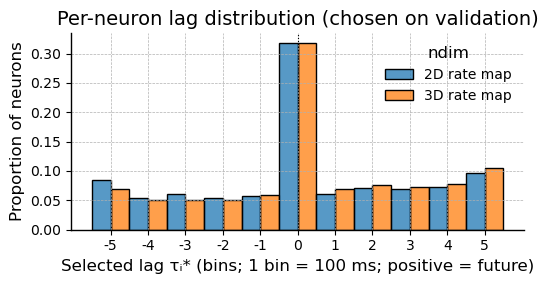

Fraction with non-zero τ* and median τ* (bins):
  2D rate map: 68.2% non-zero, median τ = 0
  3D rate map: 68.2% non-zero, median τ = 0


In [16]:
# Pool selected per-neuron lags across sessions, separately for the 2D / 3D rate maps.
lag_records = []
for (session_name, ndim), lags in chosen_lags_log.items():
    for tau in lags:
        lag_records.append({
            'session': session_name,
            'ndim': f'{ndim}D rate map',
            'lag_bins': int(tau),
        })
chosen_lags_df = pd.DataFrame(lag_records)

fig, ax = plt.subplots(1, 1, figsize=(5.5, 3))
sns.histplot(
    data=chosen_lags_df,
    x='lag_bins', hue='ndim',
    discrete=True, multiple='dodge',
    stat='proportion', common_norm=False,
    ax=ax,
)
ax.set_xlabel(
    f'Selected lag τᵢ* (bins; 1 bin = {data_config["bin_width"]*1000:.0f} ms; positive = future)'
)
ax.set_ylabel('Proportion of neurons')
ax.set_xticks(LAG_BINS)
ax.axvline(0, color='k', linewidth=0.8, linestyle=':')
ax.set_title('Per-neuron lag distribution (chosen on validation)')
plt.tight_layout()
plt.show()

print('Fraction with non-zero τ* and median τ* (bins):')
for ndim_label, sub in chosen_lags_df.groupby('ndim'):
    nonzero = (sub['lag_bins'] != 0).mean()
    median_tau = int(sub['lag_bins'].median())
    print(f'  {ndim_label}: {nonzero*100:.1f}% non-zero, median τ = {median_tau}')


## 3d. Multi-session PV-Perceiver decoders (relative + absolute)

Two PV-Perceiver decoders matching `notebooks/pv_decode.ipynb`, but consuming the **same per-session, real, simultaneously-recorded spike counts** that the NB and seq-to-seq decoders above see — *not* a bat_former pseudo-population.

**Single multi-session model per mode**, in the spirit of `Bat_Transformer_Decoder`'s session-specific readins: the Perceiver's per-neuron embedding becomes a `ParameterDict({sn: Parameter(K_sn, C)})`, while the `rate_mlp`, encoder cross-attention, processor, and decoder are all shared. Batches are per-session (the encoder's N axis is fixed within a forward pass), but the trainer round-robins per-session DataLoaders so each epoch sees a mix of session inputs in shuffled order. One Optuna study and one final checkpoint per mode.

- **Relative-time:** query grid centered on the PV-sample bin (Δt ∈ [−T_max, +T_max])
- **Absolute-time:** query grid from flight onset (t ∈ [0, T_max])

Per-mode weights cache to `./out/perceiver_real/`.

In [ ]:
# Per-session real-spike flights for the PV-Perceiver decoders.
from digitalbat.decoding import (
    extract_real_flights, suggest_perceiver_hyperparams, fixed_perceiver_config,
    train_perceiver, evaluate_perceiver, perceiver_per_timestep_df, trial_callback,
)
from digitalbat.models.perceiver import PerceiverIOTrajectoryDecoder

dt_pv = data_config['bin_width']

flights_train_real = extract_real_flights(dataloaders, meta_info_dict, 'train')
flights_valid_real = extract_real_flights(dataloaders, meta_info_dict, 'valid')
flights_test_real  = extract_real_flights(dataloaders, meta_info_dict, 'test')


def _by_session(flights):
    out = {}
    for f in flights:
        out.setdefault(f['session'], []).append(f)
    return out


flights_train_by_sess = _by_session(flights_train_real)
flights_valid_by_sess = _by_session(flights_valid_real)
flights_test_by_sess  = _by_session(flights_test_real)

# Restrict to sessions with non-trivial train + valid + test.
pv_perceiver_sessions = [
    sn for sn in dataloaders['test'].keys()
    if len(flights_train_by_sess.get(sn, [])) >= 10
    and len(flights_valid_by_sess.get(sn, [])) >= 1
    and len(flights_test_by_sess.get(sn, [])) >= 1
]
print(f'PV-Perceiver: {len(pv_perceiver_sessions)} / {len(dataloaders["test"])} sessions')

# Filter the per-session dicts down to the selected sessions and build the
# input_dim_dict that drives the model's per-session neuron embeddings.
flights_train_by_sess = {sn: flights_train_by_sess[sn] for sn in pv_perceiver_sessions}
flights_valid_by_sess = {sn: flights_valid_by_sess[sn] for sn in pv_perceiver_sessions}
flights_test_by_sess  = {sn: flights_test_by_sess[sn]  for sn in pv_perceiver_sessions}
pv_input_dim_dict = {sn: unit_num_dict[sn] for sn in pv_perceiver_sessions}

# T_max from the longest training flight across sessions (matches the convention
# in pv_decode.ipynb so the query grid covers every training trajectory).
T_max_bins = max(f['xyz'].shape[0] for f in flights_train_real)
T_max_pv = T_max_bins * dt_pv
print(f'T_max = {T_max_pv:.1f}s ({T_max_bins} bins)')
print(f'Per-session neuron counts: '
      f'min={min(pv_input_dim_dict.values())}, '
      f'max={max(pv_input_dim_dict.values())}, '
      f'sum={sum(pv_input_dim_dict.values())}')

In [ ]:
# Per-mode Optuna search.  Each trial trains one *multi-session* model:
# round-robin per-session batches feed a single Perceiver whose neuron
# embedding is a ParameterDict keyed by session.  Validation R² is
# aggregated across all sessions so the search is jointly optimal — no need
# to pick a representative session, and no per-session hyperparameter drift.
PV_N_TRIALS = 20


def make_pv_objective(time_mode):
    def objective(trial):
        config = suggest_perceiver_hyperparams(
            trial, time_mode, pv_input_dim_dict, T_max_pv, dt_pv,
        )
        val_r2, _, _ = train_perceiver(
            config, flights_train_by_sess, flights_valid_by_sess,
            device, trial=trial, verbose=False,
        )
        return val_r2
    return objective


os.makedirs('./out/perceiver_real', exist_ok=True)
pv_studies = {}
for mode in ('relative', 'absolute'):
    study_path = f'./out/perceiver_real/perceiver_real_multi_{mode}_seed_{seed}_optuna.pkl'
    if os.path.exists(study_path):
        with open(study_path, 'rb') as f:
            pv_studies[mode] = pickle.load(f)
        print(f'{mode}: loaded study with {len(pv_studies[mode].trials)} trials')
    else:
        pv_studies[mode] = optuna.create_study(
            direction='maximize',
            sampler=optuna.samplers.TPESampler(seed=42, n_startup_trials=10),
            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=20),
        )

    remaining = max(0, PV_N_TRIALS - len(pv_studies[mode].trials))
    if remaining > 0:
        optuna.logging.set_verbosity(optuna.logging.INFO)
        pv_studies[mode].optimize(
            make_pv_objective(mode), n_trials=remaining,
            show_progress_bar=True, callbacks=[trial_callback],
        )
        with open(study_path, 'wb') as f:
            pickle.dump(pv_studies[mode], f)

    print(f'{mode}: best val R² = {pv_studies[mode].best_value:.4f}')
    print(f'  best params: {pv_studies[mode].best_params}')

In [ ]:
# Final per-mode multi-session training at the searched hyperparameters.
# One model per mode, weights cached to disk.
pv_perceiver_models  = {}
pv_perceiver_configs = {}

for mode in ('relative', 'absolute'):
    best_params = pv_studies[mode].best_params
    cfg = fixed_perceiver_config(
        best_params, mode, pv_input_dim_dict, T_max_pv, dt_pv,
        max_epochs=500, warmup_steps=500,
    )
    pv_perceiver_configs[mode] = cfg
    model_path = f'./out/perceiver_real/perceiver_real_multi_{mode}_seed_{seed}.pth'
    model = PerceiverIOTrajectoryDecoder(cfg).to(device)
    if os.path.exists(model_path):
        model.load_state_dict(
            torch.load(model_path, map_location=device, weights_only=True)
        )
        print(f'[{mode}] loaded {model_path}')
    else:
        val_r2, weights, _ = train_perceiver(
            cfg, flights_train_by_sess, flights_valid_by_sess,
            device, verbose=True, random_seed=seed,
        )
        torch.save(weights, model_path)
        model.load_state_dict(weights)
        print(f'[{mode}] val R²={val_r2:.4f}, saved {model_path}')
    pv_perceiver_models[mode] = model
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'  total trainable params: {n_params:,}')

In [ ]:
# Test-time evaluation: pass the per-session test-flight dict directly to
# `evaluate_perceiver`, which iterates sessions and calls `forward(...,
# session_name=sn)` per session.  Then mean-pool snippet predictions to one
# row per (session, flight_id, t_idx) so the output joins the comparison
# DataFrames cleanly.
pv_perceiver_dfs = {}
for mode in ('relative', 'absolute'):
    snippets_df = evaluate_perceiver(
        pv_perceiver_models[mode], flights_test_by_sess,
        pv_perceiver_configs[mode], device,
    )
    per_t = perceiver_per_timestep_df(snippets_df, dt_pv)
    per_t['bat'] = per_t['session'].apply(parse_bat)
    pv_perceiver_dfs[mode] = per_t

pv_perceiver_rel_df = pv_perceiver_dfs['relative'].assign(decoder='pv_perceiver_rel')
pv_perceiver_abs_df = pv_perceiver_dfs['absolute'].assign(decoder='pv_perceiver_abs')
print(f'PV-Perceiver (relative): {len(pv_perceiver_rel_df)} test rows, '
      f'{pv_perceiver_rel_df["session"].nunique()} sessions')
print(f'PV-Perceiver (absolute): {len(pv_perceiver_abs_df)} test rows, '
      f'{pv_perceiver_abs_df["session"].nunique()} sessions')
print('\nMedian per-timestep 3D error (m):')
for mode, df in pv_perceiver_dfs.items():
    print(f'  {mode}: {df["err_3d"].median():.4f} m')

## 4. Comparison

Per-session median 2D and 3D decoding error (meters), shown as paired lines from Naive Bayes → Transformer, colored by bat.

In [ ]:
DECODER_ORDER = ['naive_bayes', 'naive_bayes_lag', 'nb_continuity', 'transformer',
                 'pv_perceiver_rel', 'pv_perceiver_abs']
# Subset used only by the synthetic comparison cells below — synthetic
# PV-Perceiver decoders aren't built (out of scope for this notebook).
SYNTHETIC_DECODER_ORDER = ['naive_bayes', 'naive_bayes_lag', 'nb_continuity', 'transformer']
DECODER_LABEL = {
    'naive_bayes': 'NB (1-step)',
    'naive_bayes_lag': 'NB (per-neuron lag)',
    'nb_continuity': 'NB + continuity',
    'transformer': 'transformer',
    'pv_perceiver_rel': 'PV-Perceiver (relative)',
    'pv_perceiver_abs': 'PV-Perceiver (absolute)',
}

all_df = pd.concat(
    [transformer_df, nb_df, nb_lag_df, nb_cont_df,
     pv_perceiver_rel_df, pv_perceiver_abs_df],
    ignore_index=True,
)
all_df['decoder'] = pd.Categorical(
    all_df['decoder'], categories=DECODER_ORDER, ordered=True,
)
median_per_session = (all_df
                      .groupby(['bat', 'session', 'decoder'], observed=True)[['err_2d', 'err_3d']]
                      .median()
                      .reset_index())
median_per_session


### 4a. Trajectory-level metric: discrete Fréchet distance

The per-timestep Euclidean error above is a *pointwise* metric — it doesn't penalise a decoder for picking the wrong overall trajectory shape so long as each individual point is close to truth. We complement it with **discrete Fréchet distance** (Eiter & Mannila 1994), the canonical "leash" metric for polyline similarity:

$$\delta_F(P, Q) = \min_{\sigma}\, \max_{(i, j) \in \sigma}\, \lVert P_i - Q_j \rVert,$$

where $\sigma$ ranges over all monotone couplings of the two polylines. Each held-out flight contributes one number per (decoder, ndim); we then take the per-session median across flights to mirror the per-timestep error aggregation. Because Fréchet allows reparameterisation, a decoder that produces the right *path* with a small temporal lag is not penalised — that's the point: we want shape mismatch, not phase mismatch (which the per-timestep error already captures).

In [ ]:
# `discrete_frechet` is provided by `digitalbat.decoding` (see imports above).
from digitalbat.decoding import discrete_frechet


TRUTH_3D = ['x_true', 'y_true', 'z_true']
# (decoder, pred_2d_cols, pred_3d_cols) — predicted-coord schema is shared
# between real-train and synthetic-train dataframes for each decoder.
DECODER_PRED_COLS = [
    ('naive_bayes',     ('x_pred_2d', 'y_pred_2d'), ('x_pred_3d', 'y_pred_3d', 'z_pred_3d')),
    ('naive_bayes_lag', ('x_pred_2d', 'y_pred_2d'), ('x_pred_3d', 'y_pred_3d', 'z_pred_3d')),
    ('nb_continuity',   ('x_pred_2d', 'y_pred_2d'), ('x_pred_3d', 'y_pred_3d', 'z_pred_3d')),
    ('transformer',     ('x_pred', 'y_pred'),       ('x_pred', 'y_pred', 'z_pred')),
    ('pv_perceiver_rel', ('x_pred', 'y_pred'),      ('x_pred', 'y_pred', 'z_pred')),
    ('pv_perceiver_abs', ('x_pred', 'y_pred'),      ('x_pred', 'y_pred', 'z_pred')),
]


def compute_frechet_per_flight(decoder_dfs):
    """decoder_dfs: list of (decoder_name, df, pred_2d_cols, pred_3d_cols).

    Returns long DataFrame: bat, session, flight_id, decoder, n_t,
    frechet_2d, frechet_3d. One row per flight per decoder.
    """
    records = []
    for decoder, df, pred_2d_cols, pred_3d_cols in decoder_dfs:
        for (bat, session, flight_id), grp in df.groupby(
                ['bat', 'session', 'flight_id'], sort=False):
            grp = grp.sort_values('t_idx')
            truth = grp[TRUTH_3D].to_numpy(dtype=np.float64)
            pred2d = grp[list(pred_2d_cols)].to_numpy(dtype=np.float64)
            pred3d = grp[list(pred_3d_cols)].to_numpy(dtype=np.float64)
            records.append({
                'bat': bat,
                'session': session,
                'flight_id': int(flight_id),
                'decoder': decoder,
                'n_t': len(grp),
                'frechet_2d': discrete_frechet(truth[:, :2], pred2d),
                'frechet_3d': discrete_frechet(truth, pred3d),
            })
    out = pd.DataFrame(records)
    out['decoder'] = pd.Categorical(
        out['decoder'], categories=DECODER_ORDER, ordered=True)
    return out


_REAL_DFS = {
    'naive_bayes': nb_df,
    'naive_bayes_lag': nb_lag_df,
    'nb_continuity': nb_cont_df,
    'transformer': transformer_df,
    'pv_perceiver_rel': pv_perceiver_rel_df,
    'pv_perceiver_abs': pv_perceiver_abs_df,
}
real_decoder_coords = [(d, _REAL_DFS[d], p2, p3) for d, p2, p3 in DECODER_PRED_COLS]
frechet_df = compute_frechet_per_flight(real_decoder_coords)

if RUN_SYNTHETIC:
    _SYN_DFS = {
        'naive_bayes': nb_df_synthetic,
        'naive_bayes_lag': nb_lag_df_synthetic,
        'nb_continuity': nb_cont_df_synthetic,
        'transformer': transformer_df_synthetic,
    }
    # Synthetic comparison stays on the original 4 decoders.
    syn_decoder_coords = [
        (d, _SYN_DFS[d], p2, p3)
        for d, p2, p3 in DECODER_PRED_COLS if d in _SYN_DFS
    ]
    frechet_df_synthetic = compute_frechet_per_flight(syn_decoder_coords)

frechet_med = (frechet_df
               .groupby(['bat', 'session', 'decoder'], observed=True)[['frechet_2d', 'frechet_3d']]
               .median()
               .reset_index())

# Merge per-session Fréchet medians into the existing per-session error table
# so the comparison plot can iterate over all four metrics.
median_per_session = median_per_session.merge(
    frechet_med, on=['bat', 'session', 'decoder'], how='left',
)
median_per_session.head()


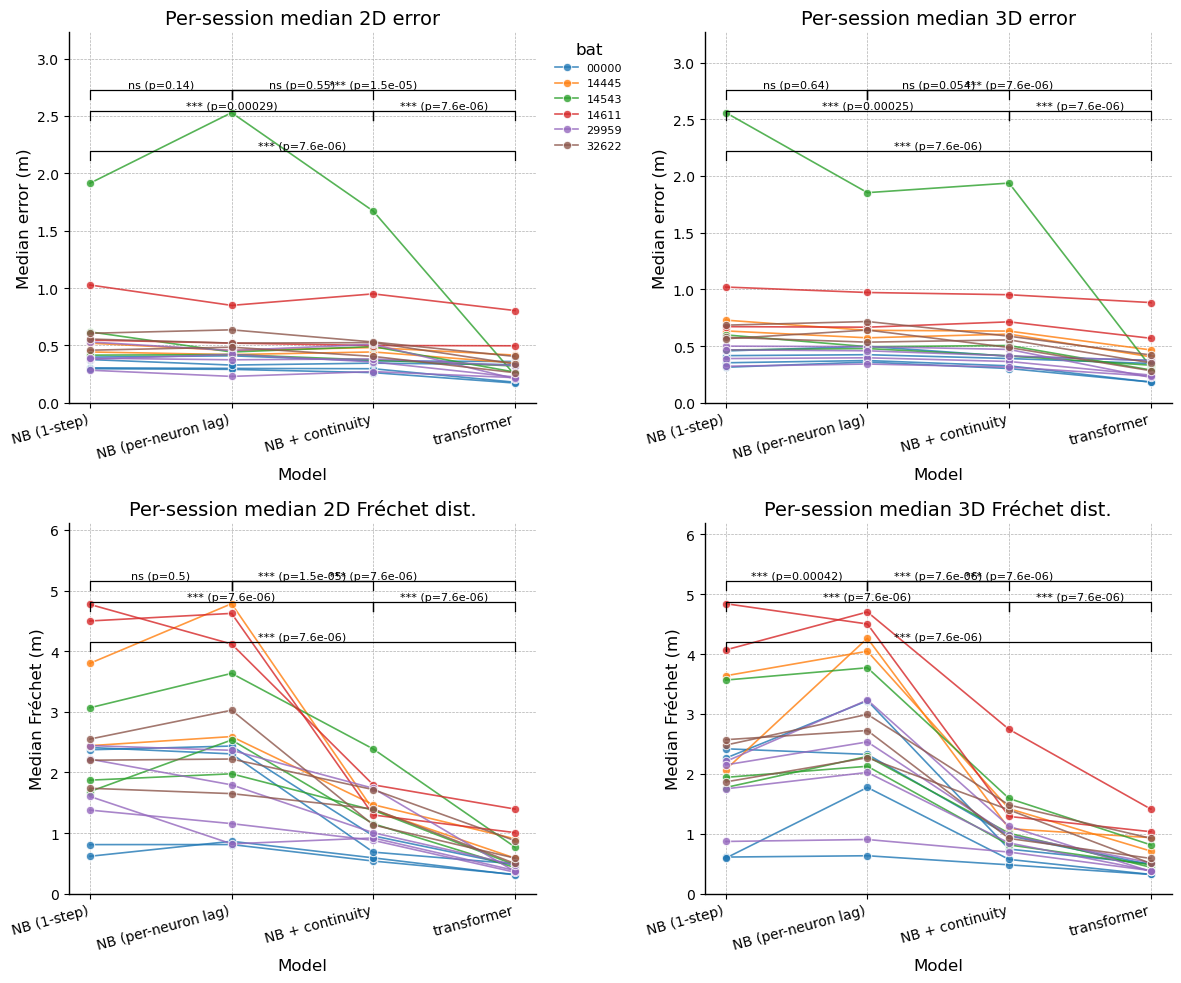

Pooled medians across all test timepoints (err) / across all flights (Fréchet):
                   err_2d    err_3d
decoder                            
naive_bayes      0.460576  0.523257
naive_bayes_lag  0.429825  0.522106
nb_continuity    0.421621  0.482017
transformer      0.309367  0.336751
                 frechet_2d  frechet_3d
decoder                                
naive_bayes        2.201741    2.136610
naive_bayes_lag    2.193990    2.590956
nb_continuity      1.155832    0.995413
transformer        0.482128    0.504170

Across-session paired Wilcoxon (2D err):
           NB (1-step) vs NB (per-neuron lag)  n=18  median(diff) = -0.0184 m,  p = 0.1415
           NB (1-step) vs NB + continuity      n=18  median(diff) = -0.0338 m,  p = 0.0002931
           NB (1-step) vs transformer          n=18  median(diff) = -0.1252 m,  p = 7.629e-06
   NB (per-neuron lag) vs NB + continuity      n=18  median(diff) = +0.0006 m,  p = 0.5509
   NB (per-neuron lag) vs transformer          n=18 

In [ ]:
from itertools import combinations
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests


def _stars(p):
    if not np.isfinite(p):
        return 'n/a'
    if p < 0.001:
        return '***'
    if p < 0.01:
        return '**'
    if p < 0.05:
        return '*'
    return 'ns'


def _annotate_bracket(ax, x1, x2, y, p, h_frac=0.03):
    """Draw a significance bracket from x1 to x2 at vertical level y."""
    h = h_frac * (ax.get_ylim()[1] - ax.get_ylim()[0])
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color='k', linewidth=0.9)
    label = f'{_stars(p)} (p={p:.2g})' if np.isfinite(p) else 'n/a'
    ax.text((x1 + x2) / 2, y + h, label, ha='center', va='bottom', fontsize=8)


def pairwise_across_session(median_df, err_col):
    """Returns a dict {(d1, d2): (W, p, n, median_diff)} for all decoder pairs.

    Pairs are ordered following DECODER_ORDER so the diff sign is consistent
    (later − earlier; negative diff means the later decoder has lower error).
    """
    wide = median_df.pivot(index='session', columns='decoder', values=err_col).dropna()
    out = {}
    for d1, d2 in combinations(DECODER_ORDER, 2):
        if d1 not in wide.columns or d2 not in wide.columns:
            continue
        diff = (wide[d2] - wide[d1]).values
        if np.all(diff == 0):
            out[(d1, d2)] = (np.nan, np.nan, len(diff), float(np.median(diff)))
        else:
            res = wilcoxon(diff, zero_method='wilcox', alternative='two-sided')
            out[(d1, d2)] = (float(res.statistic), float(res.pvalue), len(diff), float(np.median(diff)))
    return out


METRIC_PANELS = [
    ('err_2d',     'Per-session median 2D error',         'Median error (m)'),
    ('err_3d',     'Per-session median 3D error',         'Median error (m)'),
    ('frechet_2d', 'Per-session median 2D Fréchet dist.', 'Median Fréchet (m)'),
    ('frechet_3d', 'Per-session median 3D Fréchet dist.', 'Median Fréchet (m)'),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharey=False)
axes = axes.flatten()
for ax, (metric_col, title, ylabel) in zip(axes, METRIC_PANELS):
    sns.lineplot(
        data=median_per_session,
        x='decoder', y=metric_col,
        hue='bat', units='session', estimator=None,
        marker='o', linewidth=1.2, alpha=0.8,
        ax=ax,
        legend=(ax is axes[0]),
    )
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xlabel('Model')
    ax.set_xticks(range(len(DECODER_ORDER)))
    ax.set_xticklabels([DECODER_LABEL[d] for d in DECODER_ORDER], rotation=15, ha='right')
    ax.set_ylim(bottom=0)
    if ax is axes[0]:
        ax.legend(title='bat', bbox_to_anchor=(1.02, 1.0), loc='upper left',
                  fontsize=8, frameon=False)

    # Pairwise Wilcoxon brackets across sessions.
    pairs = pairwise_across_session(median_per_session, metric_col)
    pair_x = {d: i for i, d in enumerate(DECODER_ORDER)}
    y_top = ax.get_ylim()[1]
    bracket_levels = {
        ('naive_bayes', 'nb_continuity'): y_top * 0.93,
        ('nb_continuity', 'transformer'): y_top * 0.93,
        ('naive_bayes', 'transformer'): y_top * 0.8,
    }
    for (d1, d2), (w, p, n, _) in pairs.items():
        y = bracket_levels.get((d1, d2), y_top * 1.0)
        _annotate_bracket(ax, pair_x[d1], pair_x[d2], y, p)
    ax.set_ylim(top=y_top * 1.22)

plt.tight_layout()
plt.show()


print('Pooled medians across all test timepoints (err) / across all flights (Fréchet):')
print(all_df.groupby('decoder', observed=True)[['err_2d', 'err_3d']].median())
print(frechet_df.groupby('decoder', observed=True)[['frechet_2d', 'frechet_3d']].median())
for metric_col, label in [
    ('err_2d', '2D err'),
    ('err_3d', '3D err'),
    ('frechet_2d', '2D Fréchet'),
    ('frechet_3d', '3D Fréchet'),
]:
    print(f'\nAcross-session paired Wilcoxon ({label}):')
    pairs = pairwise_across_session(median_per_session, metric_col)
    for (d1, d2), (w, p, n, mdiff) in pairs.items():
        print(f'  {DECODER_LABEL[d1]:>20} vs {DECODER_LABEL[d2]:<20}'
              f' n={n:2d}  median(diff) = {mdiff:+.4f} m,  p = {p:.4g}')


### 4a. Per-session paired tests on individual timepoints

The line-plot annotations are *across-session* paired Wilcoxon (one observation per session, n = n_sessions). Below we additionally do **within-session** paired Wilcoxon on individual test timepoints, joined on `(flight_id, t_idx)` so each row is a triplet (NB, NB+continuity, transformer) at the same timepoint.

Caveat: consecutive timepoints within a flight are temporally correlated, so within-session p-values are *anti-conservative*. We Benjamini–Hochberg correct across sessions × decoder pairs to keep that visible. The across-session Wilcoxon (in the printout above) is the cleaner inference; this table just shows where each effect comes from.

In [ ]:
def _wilcoxon_safe(diff):
    diff = np.asarray(diff)
    diff = diff[np.isfinite(diff)]
    if diff.size < 1 or np.all(diff == 0):
        return np.nan, np.nan
    res = wilcoxon(diff, zero_method='wilcox', alternative='two-sided')
    return float(res.statistic), float(res.pvalue)


# Build long-form joined table: one row per (session, flight_id, t_idx, decoder).
join_keys = ['session', 'flight_id', 't_idx']
err_cols = ['err_2d', 'err_3d']
long_df = (
    all_df[['bat', *join_keys, 'decoder', *err_cols]]
    .copy()
)

# Pivot: each row = (session, flight, t), columns = decoders × err.
wide_per_t = long_df.pivot_table(
    index=['bat', *join_keys],
    columns='decoder',
    values=err_cols,
    observed=True,
).dropna()

per_session_rows = []
for session_name, grp in wide_per_t.groupby(level='session'):
    bat = grp.index.get_level_values('bat')[0]
    row = {'session': session_name, 'bat': bat, 'n_paired': len(grp)}
    for err_col in err_cols:
        for d1, d2 in combinations(DECODER_ORDER, 2):
            if (err_col, d1) not in grp.columns or (err_col, d2) not in grp.columns:
                continue
            diff = grp[(err_col, d2)].values - grp[(err_col, d1)].values
            w, p = _wilcoxon_safe(diff)
            tag = f'{d1[:3]}-vs-{d2[:3]}_{err_col[-2:]}'
            row[f'med_diff_{tag}'] = float(np.median(diff))
            row[f'p_{tag}'] = p
    per_session_rows.append(row)

per_session_stats = pd.DataFrame(per_session_rows)

# BH-correct each p-column separately across sessions.
p_cols = [c for c in per_session_stats.columns if c.startswith('p_')]
for col in p_cols:
    pvals = per_session_stats[col].fillna(1.0).values
    _, q, _, _ = multipletests(pvals, method='fdr_bh')
    per_session_stats[col.replace('p_', 'q_')] = q

# Sort by transformer-vs-NB 2D p-value (the typical headline comparison).
sort_col = 'p_nai-vs-tra_2d'
if sort_col in per_session_stats.columns:
    per_session_stats = per_session_stats.sort_values(sort_col).reset_index(drop=True)

per_session_stats

,session,bat,n_paired,med_diff_nai-vs-nai_2d,p_nai-vs-nai_2d,med_diff_nai-vs-nb__2d,p_nai-vs-nb__2d,med_diff_nai-vs-tra_2d,p_nai-vs-tra_2d,med_diff_nb_-vs-tra_2d,...,med_diff_nb_-vs-tra_3d,p_nb_-vs-tra_3d,q_nai-vs-nai_2d,q_nai-vs-nb__2d,q_nai-vs-tra_2d,q_nb_-vs-tra_2d,q_nai-vs-nai_3d,q_nai-vs-nb__3d,q_nai-vs-tra_3d,q_nb_-vs-tra_3d
0,Dataset_3_29959_240402,29959,574,0.000000,0.321727,0.000000,1.951408e-01,-0.200104,1.272085e-39,-0.228375,...,-0.202704,4.932879e-44,0.477325,0.350508,2.289753e-38,2.825245e-41,0.255884,0.003918,5.183072e-44,8.879182e-43
1,Dataset_1_32622_231010,32622,458,0.000000,0.984343,-0.001791,8.262514e-04,-0.188423,6.506853e-32,-0.132194,...,-0.178123,6.595743e-31,0.984343,0.004958,5.856167e-31,3.494519e-22,0.297351,0.000001,2.603136e-45,5.936169e-30
2,Dataset_3_29959_240403,29959,540,0.000000,0.425895,0.000000,2.141996e-01,-0.164698,1.955642e-29,-0.126212,...,-0.113486,8.863979e-22,0.547580,0.350508,1.173385e-28,2.649013e-23,0.999277,0.414306,6.579663e-31,1.994395e-21
3,Dataset_3_14543_240419,14543,199,0.025486,0.008281,-0.173916,1.966946e-07,-1.910456,1.357656e-26,-1.272734,...,-1.382960,6.164050e-23,0.028161,0.000004,6.109450e-26,8.437070e-24,0.000089,0.374716,4.799145e-23,1.849215e-22
4,Dataset_3_14543_240421,14543,396,0.000000,0.003712,0.000000,1.853678e-01,-0.167857,4.326918e-24,-0.189019,...,-0.212966,5.894698e-29,0.022270,0.350508,1.557691e-23,7.667366e-20,0.034817,0.865144,6.197464e-26,2.652614e-28
5,Dataset_3_00000_240403,00000,388,0.000000,0.344735,0.000000,2.662514e-01,-0.113993,8.608308e-23,-0.097969,...,-0.147325,2.146356e-30,0.477325,0.399377,2.582492e-22,6.965194e-18,0.877069,0.192265,1.797917e-33,1.287814e-29
6,Dataset_1_32622_231009,32622,412,0.000000,0.697021,-0.032187,1.974555e-04,-0.172877,6.977954e-20,-0.097208,...,-0.158353,1.420949e-14,0.836426,0.001777,1.794331e-19,3.882685e-09,0.877069,0.000100,1.385057e-26,2.557708e-14
7,Dataset_3_14543_240420,14543,542,0.000000,0.941174,0.000000,1.023154e-01,-0.095483,2.614572e-15,-0.062918,...,-0.084107,5.509316e-11,0.984343,0.263097,5.882788e-15,9.992906e-11,0.865205,0.003918,1.452895e-19,8.263974e-11
8,Dataset_1_32622_231007,32622,535,0.000000,0.061657,0.000000,7.946358e-01,-0.120003,8.767361e-14,-0.119446,...,-0.159928,6.784298e-24,0.123314,0.800569,1.753472e-13,3.222929e-13,0.085763,0.374716,2.177246e-14,2.442347e-23
9,Dataset_2_14445_231208,14445,591,0.000000,0.072903,0.000000,7.880187e-01,-0.056320,6.729883e-09,-0.051534,...,-0.166389,8.856786e-23,0.131226,0.800569,1.211379e-08,1.392348e-09,0.140160,0.370039,1.948461e-20,2.277459e-22


### 4b. Real vs synthetic training data — per-decoder comparison


In [ ]:
# Per-decoder real-vs-synthetic comparison.  Each row is a metric
# (2D / 3D position error and 2D / 3D Fréchet distance); each column is
# one decoder.  Lines connect paired sessions, colored by bat.  A
# Wilcoxon signed-rank test (synthetic − real) is annotated above each
# panel; positive Δ = synthetic worse than real.
if not RUN_SYNTHETIC:
    print('Skipping real-vs-synthetic comparison (RUN_SYNTHETIC=False).')
else:
    # --- Build per-session table with all 4 metrics × 2 modes × 4 decoders.
    err_dfs = {
        ('real', 'naive_bayes'):     nb_df,
        ('real', 'naive_bayes_lag'): nb_lag_df,
        ('real', 'nb_continuity'):   nb_cont_df,
        ('real', 'transformer'):     transformer_df,
        ('synthetic', 'naive_bayes'):     nb_df_synthetic,
        ('synthetic', 'naive_bayes_lag'): nb_lag_df_synthetic,
        ('synthetic', 'nb_continuity'):   nb_cont_df_synthetic,
        ('synthetic', 'transformer'):     transformer_df_synthetic,
    }
    err_pieces = []
    for (mode, decoder), df in err_dfs.items():
        med = (df.groupby(['bat', 'session'], observed=True)[['err_2d', 'err_3d']]
               .median().reset_index())
        med['decoder'] = decoder
        med['mode'] = mode
        err_pieces.append(med)
    err_med_long = pd.concat(err_pieces, ignore_index=True)

    fre_pieces = []
    for mode, df in [('real', frechet_df), ('synthetic', frechet_df_synthetic)]:
        med = (df.groupby(['bat', 'session', 'decoder'], observed=True)[['frechet_2d', 'frechet_3d']]
               .median().reset_index())
        med['mode'] = mode
        fre_pieces.append(med)
    fre_med_long = pd.concat(fre_pieces, ignore_index=True)

    rs_med = err_med_long.merge(
        fre_med_long, on=['bat', 'session', 'decoder', 'mode'], how='left')
    rs_med = rs_med[rs_med['decoder'].isin(SYNTHETIC_DECODER_ORDER)].copy()
    rs_med['decoder'] = pd.Categorical(
        rs_med['decoder'], categories=SYNTHETIC_DECODER_ORDER, ordered=True)
    rs_med['mode'] = pd.Categorical(
        rs_med['mode'], categories=['real', 'synthetic'], ordered=True)

    # --- Plot: 4 metric rows × 4 decoder columns.
    metric_specs = [
        ('err_2d',     '2D error',    'session median 2D err (m)'),
        ('err_3d',     '3D error',    'session median 3D err (m)'),
        ('frechet_2d', '2D Fréchet',  'session median 2D Fréchet (m)'),
        ('frechet_3d', '3D Fréchet',  'session median 3D Fréchet (m)'),
    ]

    fig, axes = plt.subplots(
        len(metric_specs), len(SYNTHETIC_DECODER_ORDER),
        figsize=(3.2 * len(SYNTHETIC_DECODER_ORDER), 3.0 * len(metric_specs)),
        sharex=True, sharey='row',
    )
    # Pass 1: plot + titles + collect p-values.  With sharey='row',
    # set_ylim propagates across the row, so deferring ylim/bracket
    # placement to a second pass avoids the 1.2**ncol compounding.
    p_by_cell = {}
    for col, decoder in enumerate(SYNTHETIC_DECODER_ORDER):
        for row, (metric, short, _ylabel) in enumerate(metric_specs):
            ax = axes[row, col]
            sub = rs_med[rs_med['decoder'] == decoder]
            sns.lineplot(
                data=sub, x='mode', y=metric,
                hue='bat', units='session', estimator=None,
                marker='o', linewidth=1.2, alpha=0.85, ax=ax,
                legend=(row == 0 and col == len(SYNTHETIC_DECODER_ORDER) - 1),
            )
            wide = sub.pivot(index='session', columns='mode', values=metric).dropna()
            if len(wide) > 0:
                diff = (wide['synthetic'] - wide['real']).values
                _, p = _wilcoxon_safe(diff)
                title = (f'{DECODER_LABEL[decoder]}'
                         if row == 0 else short)
                ax.set_title(
                    f'{title}\nΔ={float(np.median(diff)):+.3f} m, n={len(wide)}',
                    fontsize=10,
                )
                p_by_cell[(row, col)] = p
            ax.set_xlabel('train data' if row == len(metric_specs) - 1 else '')
            ax.set_ylabel(_ylabel if col == 0 else '')
            leg = ax.get_legend()
            if leg is not None and not (row == 0 and col == len(SYNTHETIC_DECODER_ORDER) - 1):
                leg.remove()

    # Pass 2: per-row ylim from data max + headroom, then place brackets.
    for row, (metric, _short, _ylabel) in enumerate(metric_specs):
        row_max = float(rs_med[metric].max())
        y_top = row_max * 1.20
        for col in range(len(SYNTHETIC_DECODER_ORDER)):
            ax = axes[row, col]
            ax.set_ylim(0, y_top)
            p = p_by_cell.get((row, col))
            if p is not None and np.isfinite(p):
                _annotate_bracket(ax, 0, 1, row_max * 1.05, p)

    if axes[0, -1].get_legend() is not None:
        axes[0, -1].legend(
            title='bat', bbox_to_anchor=(1.02, 1.0), loc='upper left',
            fontsize=8, frameon=False,
        )
    fig.suptitle(
        'Real vs synthetic training data: per-session metrics',
        fontsize=12, y=1.005,
    )
    plt.tight_layout()
    plt.show()

    # Print Wilcoxon summary alongside the plot.
    print('Synthetic minus real (per-session median): positive = synthetic worse.')
    for decoder in SYNTHETIC_DECODER_ORDER:
        for metric, short, _ in metric_specs:
            sub = rs_med[rs_med['decoder'] == decoder]
            wide = sub.pivot(index='session', columns='mode', values=metric).dropna()
            if len(wide) == 0:
                continue
            diff = (wide['synthetic'] - wide['real']).values
            _, p = _wilcoxon_safe(diff)
            print(f'  {DECODER_LABEL[decoder]:>22}  {short:>11}: '
                  f'n={len(wide):2d}  Δmedian={float(np.median(diff)):+.4f} m  p={p:.3g}')


### 4c. Aggregate view: x = model, style = dataset

One panel per metric.  Sessions are shown as small jittered points
(each point = one session's median test metric); the bar shows the
median ± IQR pooled across sessions for each (decoder, mode).  Brackets
report paired Wilcoxon (synthetic − real) per decoder.


In [ ]:
# x = decoder, hue = train-data mode (real / synthetic).  Reuses
# `rs_med` built in cell 4b above.
if not RUN_SYNTHETIC:
    print('Skipping aggregate plot (RUN_SYNTHETIC=False).')
else:
    metric_specs = [
        ('err_2d',     '2D error',   'median 2D err (m)'),
        ('err_3d',     '3D error',   'median 3D err (m)'),
        ('frechet_2d', '2D Fréchet', 'median 2D Fréchet (m)'),
        ('frechet_3d', '3D Fréchet', 'median 3D Fréchet (m)'),
    ]
    mode_palette = {'real': '#4c72b0', 'synthetic': '#dd8452'}

    fig, axes = plt.subplots(1, len(metric_specs),
                             figsize=(3.6 * len(metric_specs), 4.2))
    for col, (metric, short, ylabel) in enumerate(metric_specs):
        ax = axes[col]
        sub = rs_med[['bat', 'session', 'decoder', 'mode', metric]].dropna()
        sns.stripplot(
            data=sub, x='decoder', y=metric, hue='mode',
            order=SYNTHETIC_DECODER_ORDER, hue_order=['real', 'synthetic'],
            palette=mode_palette, dodge=True, alpha=0.45, size=4,
            jitter=0.18, ax=ax, legend=(col == 0),
        )
        sns.pointplot(
            data=sub, x='decoder', y=metric, hue='mode',
            order=SYNTHETIC_DECODER_ORDER, hue_order=['real', 'synthetic'],
            palette=mode_palette, dodge=0.4, errorbar=('pi', 50),
            markers='_', linestyle='none', err_kws={'linewidth': 1.5},
            ax=ax, legend=False,
        )
        ax.set_title(short)
        ax.set_xlabel('')
        ax.set_ylabel(ylabel if col == 0 else '')
        ax.set_xticks(range(len(SYNTHETIC_DECODER_ORDER)))
        ax.set_xticklabels([DECODER_LABEL[d] for d in SYNTHETIC_DECODER_ORDER],
                           rotation=20, ha='right')
        ax.set_ylim(bottom=0)
        # Paired Wilcoxon (synthetic − real) per decoder.
        y_top = ax.get_ylim()[1]
        for i, decoder in enumerate(SYNTHETIC_DECODER_ORDER):
            wide = (sub[sub['decoder'] == decoder]
                    .pivot(index='session', columns='mode', values=metric)
                    .dropna())
            if len(wide) == 0:
                continue
            diff = (wide['synthetic'] - wide['real']).values
            _, p = _wilcoxon_safe(diff)
            if np.isfinite(p):
                _annotate_bracket(ax, i - 0.2, i + 0.2, y_top * 0.92, p)
        ax.set_ylim(top=y_top * 1.18)
        if col == 0:
            ax.legend(title='train data', loc='upper left', frameon=False,
                      fontsize=9)
    fig.suptitle('Per-decoder summary: real vs synthetic training data',
                 fontsize=12, y=1.02)
    plt.tight_layout()
    plt.show()


## 5. Per-session decoded trajectories

For each session, draw each test flight as a polyline (timepoints connected in temporal order). Truth shown on every panel; each decoder gets its own column. Black = ground truth, blue = transformer, orange = NB (1-step), green = NB+continuity.

In [ ]:
from digitalbat.decoding import (
    plot_trajectory_grid, plot_trajectory_zoom_3d, polylines_from_per_timestep_df,
)


DECODER_PANELS = [
    ('naive_bayes',      'NB (1-step)',            'tab:orange'),
    ('naive_bayes_lag',  'NB (per-neuron lag)',    'tab:purple'),
    ('nb_continuity',    'NB + continuity',        'tab:green'),
    ('transformer',      'Seq-to-seq',             'tab:blue'),
    ('pv_perceiver_rel', 'PV-Perceiver (rel)',     'tab:red'),
    ('pv_perceiver_abs', 'PV-Perceiver (abs)',     'tab:cyan'),
]
# Subset reused by the train-side trajectory plot (no PV-Perceiver train df).
ORIG_DECODER_PANELS = DECODER_PANELS[:4]


def _polylines_2d(df):
    return polylines_from_per_timestep_df(
        df,
        pred_cols=('x_pred_2d', 'y_pred_2d') if 'x_pred_2d' in df.columns else ('x_pred', 'y_pred'),
        truth_cols=('x_true', 'y_true'),
        sort_by='t_idx',
    )


def _polylines_3d(df):
    return polylines_from_per_timestep_df(
        df,
        pred_cols=('x_pred_3d', 'y_pred_3d', 'z_pred_3d') if 'x_pred_3d' in df.columns else ('x_pred', 'y_pred', 'z_pred'),
        truth_cols=('x_true', 'y_true', 'z_true'),
        sort_by='t_idx',
    )


per_decoder_test = {
    'naive_bayes':      nb_df,
    'naive_bayes_lag':  nb_lag_df,
    'nb_continuity':    nb_cont_df,
    'transformer':      transformer_df,
    'pv_perceiver_rel': pv_perceiver_rel_df,
    'pv_perceiver_abs': pv_perceiver_abs_df,
}
polylines_2d_test = {dk: _polylines_2d(df) for dk, df in per_decoder_test.items()}
polylines_3d_test = {dk: _polylines_3d(df) for dk, df in per_decoder_test.items()}
session_list = list(dataloaders['test'].keys())

plot_trajectory_grid(
    session_list, DECODER_PANELS, polylines_2d_test,
    dim=2,
    session_label_fn=lambda s: s[8:],
    suptitle='Per-session test trajectories (2D)',
)
plt.show()

In [ ]:
per_decoder_train = {
    'naive_bayes':     nb_train_df,
    'naive_bayes_lag': nb_lag_train_df,
    'nb_continuity':   nb_cont_train_df,
    'transformer':     transformer_train_df,
}
polylines_3d_train = {dk: _polylines_3d(df) for dk, df in per_decoder_train.items()}

for split_label, polylines in [('test', polylines_3d_test), ('train', polylines_3d_train)]:
    panels = ORIG_DECODER_PANELS if split_label == 'train' else DECODER_PANELS
    plot_trajectory_grid(
        session_list, panels, polylines,
        dim=3,
        session_label_fn=lambda s: s[8:],
        suptitle=f'Per-session {split_label} trajectories (3D)',
    )
    plt.show()

In [ ]:
zoom_session = 'Dataset_3_00000_240403'
plot_trajectory_zoom_3d(
    zoom_session, DECODER_PANELS, polylines_3d_test,
    suptitle=f'Test trajectories — {zoom_session}',
)
plt.show()